In [1]:
import matplotlib.pyplot as plt
from matplotlib import style
import numpy as np
import pandas as pd
from matplotlib.path import Path
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import math
import re
import matplotlib.image as mpimg
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.gridspec as gridspec

location = 'upper right'
linewidth = 1
size=10
style.use("ggplot")
# plt.style.use('seaborn-dark-palette')
plt.style.use('seaborn-whitegrid')

C:\Users\921636\AppData\Local\Temp\1\ipykernel_13988\2278653409.py:19: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-whitegrid')


In [2]:
# Define a function to extract the network name
def extract_network_name(var_name):
    # Find the start and end positions of the tuple within the string
    start = var_name.find('(')
    end = var_name.find(')')
    if start != -1 and end != -1:
        # Extract the tuple string and split it by comma
        tuple_str = var_name[start+1:end]
        tuple_parts = tuple_str.split(',')
        # The network name is the last part of the tuple
        network_name = tuple_parts[-1].strip().replace("'", "")
        return network_name
    return None

def extract_node_number(var_name):
    # Use regular expression to find the node number
    match = re.search(r'(\d+)', var_name)
    if match:
        return int(match.group())
    return None

demand = {'Gas': {'Gas_node_3': 217.3, 'Gas_node_4': 154.9, 'Gas_node_5': 266.8, 'Gas_node_6': 17.7, 'Gas_node_7': 22.9, 'Gas_node_8': 68.6, 'Gas_node_9': 47.0, 'Gas_node_10': 13.4, 'Gas_node_11': 3.4, 'Gas_node_12': 14.2, 'Gas_node_13': 25.3, 'Gas_node_14': 11.5, 'Gas_node_15': 137.0}, 'Power': {'Power_node_9': 9.777975497, 'Power_node_10': 53.84153027, 'Power_node_11': 27.10716836, 'Power_node_12': 19.66908817, 'Power_node_13': 55.7552359, 'Power_node_14': 16.72668359, 'Power_node_15': 16.75704501, 'Power_node_16': 10.80638959, 'Power_node_17': 0.316401109, 'Power_node_18': 6.252251204, 'Power_node_19': 29.64691932, 'Power_node_20': 32.47823896, 'Power_node_21': 36.98167494, 'Power_node_22': 25.97081786, 'Power_node_23': 37.7794295, 'Power_node_24': 58.98713969, 'Power_node_25': 48.0024627, 'Power_node_26': 19.09654231, 'Power_node_27': 32.69737324, 'Power_node_28': 25.40134154, 'Power_node_29': 4.382616987, 'Power_node_30': 22.90754838, 'Power_node_31': 22.20482407, 'Power_node_32': 32.74613032, 'Power_node_33': 32.10891415, 'Power_node_34': 9.796453251, 'Power_node_35': 16.02433749, 'Power_node_36': 13.44535955, 'Power_node_37': 19.81595579, 'Power_node_38': 12.95349404, 'Power_node_39': 22.71395364, 'Power_node_40': 16.35711169, 'Power_node_41': 6.208486796, 'Power_node_42': 0.201951604, 'Power_node_43': 2.773539927, 'Power_node_44': 4.515513246, 'Power_node_45': 20.54463635, 'Power_node_46': 32.95556248, 'Power_node_47': 24.73559969, 'Power_node_48': 30.4131649, 'Power_node_49': 53.68724181, 'Power_node_50': 34.45589509}, 'Water': {'Water_node_15': 42.651, 'Water_node_16': 55.167, 'Water_node_17': 50.204, 'Water_node_18': 23.187, 'Water_node_19': 72.332, 'Water_node_20': 7.493, 'Water_node_21': 14.845, 'Water_node_22': 42.635, 'Water_node_23': 23.465, 'Water_node_24': 117.6, 'Water_node_25': 25.743, 'Water_node_26': 31.052, 'Water_node_27': 64.456, 'Water_node_28': 44.205, 'Water_node_29': 40.688, 'Water_node_30': 94.542, 'Water_node_31': 15.775, 'Water_node_32': 18.855, 'Water_node_33': 38.4, 'Water_node_34': 100.632, 'Water_node_35': 21.836, 'Water_node_36': 4.787, 'Water_node_37': 0.503, 'Water_node_38': 18.15, 'Water_node_39': 8.237, 'Water_node_40': 1.483, 'Water_node_41': 4.046, 'Water_node_42': 2.958, 'Water_node_43': 7.225, 'Water_node_44': 0.422, 'Water_node_45': 1.738, 'Water_node_46': 0.985, 'Water_node_47': 1.408, 'Water_node_48': 2.295}}

# Create a new dictionary to store the modified keys
modified_demand = {}
for energy_type, inner_dict in demand.items():
    # Create a new inner dictionary with modified keys
    modified_inner_dict = {int(node.split('_')[-1]): value for node, value in inner_dict.items()}
    # Store the modified inner dictionary in the new dictionary
    modified_demand[energy_type] = modified_inner_dict
demand = modified_demand

# Dictionary to store max demand values for each key
max_demand = {}

# Iterate over each key in the demand dictionary
for k, inner_dict in demand.items():
    # Compute the max demand value for the current key
    max_value = max(inner_dict.values())
    # Store the max value in the max_demand dictionary
    max_demand[k] = max_value

# # Print the max demand for each key
# print(max_demand)

demand_nodes = {k:[i for i in demand[k].keys()] for k in demand.keys()}

N_k_s = {'Gas': ['Gas_node_0', 'Gas_node_1', 'Gas_node_2'], 'Power': ['Power_node_0', 'Power_node_1', 'Power_node_2', 'Power_node_3', 'Power_node_4', 'Power_node_5', 'Power_node_6', 'Power_node_7', 'Power_node_8'], 'Water': ['Water_node_0', 'Water_node_1', 'Water_node_2', 'Water_node_3', 'Water_node_4', 'Water_node_5', 'Water_node_6', 'Water_node_7', 'Water_node_8', 'Water_node_9', 'Water_node_10', 'Water_node_11', 'Water_node_12', 'Water_node_13', 'Water_node_14']}

modified_N_k_s = {}
for energy_type, inner_list in N_k_s.items():
    # Create a new inner dictionary with modified keys
    modified_inner_list = [int(node.split('_')[-1]) for node in inner_list]
    # Store the modified inner dictionary in the new dictionary
    modified_N_k_s[energy_type] = modified_inner_list
supply_nodes = modified_N_k_s

N_k_nod = {'Gas': [], 'Power': ['Power_node_51', 'Power_node_52', 'Power_node_53', 'Power_node_54', 'Power_node_55', 'Power_node_56', 'Power_node_57', 'Power_node_58', 'Power_node_59', 'Power_node_60', 'Power_node_61', 'Power_node_62', 'Power_node_63', 'Power_node_64', 'Power_node_65', 'Power_node_66', 'Power_node_67', 'Power_node_68', 'Power_node_69', 'Power_node_70', 'Power_node_71', 'Power_node_72', 'Power_node_73', 'Power_node_74'], 'Water': []}

modified_N_k_nod = {}
for energy_type, inner_list in N_k_nod.items():
    # Create a new inner dictionary with modified keys
    modified_inner_list = [int(node.split('_')[-1]) for node in inner_list]
    # Store the modified inner dictionary in the new dictionary
    modified_N_k_nod[energy_type] = modified_inner_list
transshipment_nodes = modified_N_k_nod

A_k = {'Gas': [('Gas_node_9', 'Gas_node_0'), ('Gas_node_0', 'Gas_node_3'), ('Gas_node_0', 'Gas_node_5'), ('Gas_node_5', 'Gas_node_1'), ('Gas_node_1', 'Gas_node_13'), ('Gas_node_13', 'Gas_node_7'), ('Gas_node_7', 'Gas_node_8'), ('Gas_node_8', 'Gas_node_15'), ('Gas_node_5', 'Gas_node_4'), ('Gas_node_4', 'Gas_node_10'), ('Gas_node_10', 'Gas_node_5'), ('Gas_node_10', 'Gas_node_2'), ('Gas_node_2', 'Gas_node_11'), ('Gas_node_11', 'Gas_node_12'), ('Gas_node_11', 'Gas_node_6'), ('Gas_node_6', 'Gas_node_13'), ('Gas_node_13', 'Gas_node_14'), ('Gas_node_0', 'Gas_node_9'), ('Gas_node_3', 'Gas_node_0'), ('Gas_node_5', 'Gas_node_0'), ('Gas_node_1', 'Gas_node_5'), ('Gas_node_13', 'Gas_node_1'), ('Gas_node_7', 'Gas_node_13'), ('Gas_node_8', 'Gas_node_7'), ('Gas_node_15', 'Gas_node_8'), ('Gas_node_4', 'Gas_node_5'), ('Gas_node_10', 'Gas_node_4'), ('Gas_node_5', 'Gas_node_10'), ('Gas_node_2', 'Gas_node_10'), ('Gas_node_11', 'Gas_node_2'), ('Gas_node_12', 'Gas_node_11'), ('Gas_node_6', 'Gas_node_11'), ('Gas_node_13', 'Gas_node_6'), ('Gas_node_14', 'Gas_node_13')], 'Power': [('Power_node_71', 'Power_node_7'), ('Power_node_71', 'Power_node_70'), ('Power_node_71', 'Power_node_68'), ('Power_node_1', 'Power_node_31'), ('Power_node_12', 'Power_node_10'), ('Power_node_9', 'Power_node_10'), ('Power_node_12', 'Power_node_9'), ('Power_node_36', 'Power_node_3'), ('Power_node_34', 'Power_node_36'), ('Power_node_34', 'Power_node_18'), ('Power_node_18', 'Power_node_17'), ('Power_node_35', 'Power_node_3'), ('Power_node_35', 'Power_node_33'), ('Power_node_2', 'Power_node_33'), ('Power_node_28', 'Power_node_15'), ('Power_node_7', 'Power_node_8'), ('Power_node_72', 'Power_node_25'), ('Power_node_25', 'Power_node_62'), ('Power_node_73', 'Power_node_71'), ('Power_node_69', 'Power_node_39'), ('Power_node_68', 'Power_node_44'), ('Power_node_6', 'Power_node_67'), ('Power_node_39', 'Power_node_66'), ('Power_node_66', 'Power_node_57'), ('Power_node_40', 'Power_node_57'), ('Power_node_57', 'Power_node_38'), ('Power_node_3', 'Power_node_55'), ('Power_node_55', 'Power_node_54'), ('Power_node_54', 'Power_node_65'), ('Power_node_54', 'Power_node_22'), ('Power_node_65', 'Power_node_21'), ('Power_node_65', 'Power_node_5'), ('Power_node_5', 'Power_node_48'), ('Power_node_63', 'Power_node_49'), ('Power_node_4', 'Power_node_63'), ('Power_node_20', 'Power_node_4'), ('Power_node_50', 'Power_node_20'), ('Power_node_61', 'Power_node_50'), ('Power_node_37', 'Power_node_31'), ('Power_node_64', 'Power_node_37'), ('Power_node_5', 'Power_node_64'), ('Power_node_5', 'Power_node_64'), ('Power_node_61', 'Power_node_13'), ('Power_node_13', 'Power_node_11'), ('Power_node_74', 'Power_node_4'), ('Power_node_69', 'Power_node_67'), ('Power_node_70', 'Power_node_72'), ('Power_node_60', 'Power_node_1'), ('Power_node_60', 'Power_node_12'), ('Power_node_58', 'Power_node_60'), ('Power_node_58', 'Power_node_30'), ('Power_node_14', 'Power_node_2'), ('Power_node_2', 'Power_node_15'), ('Power_node_15', 'Power_node_59'), ('Power_node_27', 'Power_node_59'), ('Power_node_59', 'Power_node_14'), ('Power_node_32', 'Power_node_30'), ('Power_node_32', 'Power_node_31'), ('Power_node_19', 'Power_node_21'), ('Power_node_52', 'Power_node_18'), ('Power_node_52', 'Power_node_53'), ('Power_node_53', 'Power_node_16'), ('Power_node_53', 'Power_node_2'), ('Power_node_51', 'Power_node_52'), ('Power_node_29', 'Power_node_51'), ('Power_node_0', 'Power_node_51'), ('Power_node_0', 'Power_node_17'), ('Power_node_0', 'Power_node_56'), ('Power_node_28', 'Power_node_56'), ('Power_node_56', 'Power_node_26'), ('Power_node_26', 'Power_node_9'), ('Power_node_74', 'Power_node_47'), ('Power_node_4', 'Power_node_46'), ('Power_node_8', 'Power_node_73'), ('Power_node_72', 'Power_node_73'), ('Power_node_68', 'Power_node_45'), ('Power_node_70', 'Power_node_69'), ('Power_node_38', 'Power_node_3'), ('Power_node_24', 'Power_node_5'), ('Power_node_24', 'Power_node_67'), ('Power_node_55', 'Power_node_39'), ('Power_node_6', 'Power_node_66'), ('Power_node_6', 'Power_node_44'), ('Power_node_23', 'Power_node_45'), ('Power_node_62', 'Power_node_63'), ('Power_node_4', 'Power_node_62'), ('Power_node_11', 'Power_node_74'), ('Power_node_1', 'Power_node_61'), ('Power_node_14', 'Power_node_58'), ('Power_node_49', 'Power_node_23'), ('Power_node_41', 'Power_node_6'), ('Power_node_42', 'Power_node_6'), ('Power_node_43', 'Power_node_6'), ('Power_node_7', 'Power_node_71'), ('Power_node_70', 'Power_node_71'), ('Power_node_68', 'Power_node_71'), ('Power_node_31', 'Power_node_1'), ('Power_node_10', 'Power_node_12'), ('Power_node_10', 'Power_node_9'), ('Power_node_9', 'Power_node_12'), ('Power_node_3', 'Power_node_36'), ('Power_node_36', 'Power_node_34'), ('Power_node_18', 'Power_node_34'), ('Power_node_17', 'Power_node_18'), ('Power_node_3', 'Power_node_35'), ('Power_node_33', 'Power_node_35'), ('Power_node_33', 'Power_node_2'), ('Power_node_15', 'Power_node_28'), ('Power_node_8', 'Power_node_7'), ('Power_node_25', 'Power_node_72'), ('Power_node_62', 'Power_node_25'), ('Power_node_71', 'Power_node_73'), ('Power_node_39', 'Power_node_69'), ('Power_node_44', 'Power_node_68'), ('Power_node_67', 'Power_node_6'), ('Power_node_66', 'Power_node_39'), ('Power_node_57', 'Power_node_66'), ('Power_node_57', 'Power_node_40'), ('Power_node_38', 'Power_node_57'), ('Power_node_55', 'Power_node_3'), ('Power_node_54', 'Power_node_55'), ('Power_node_65', 'Power_node_54'), ('Power_node_22', 'Power_node_54'), ('Power_node_21', 'Power_node_65'), ('Power_node_5', 'Power_node_65'), ('Power_node_48', 'Power_node_5'), ('Power_node_49', 'Power_node_63'), ('Power_node_63', 'Power_node_4'), ('Power_node_4', 'Power_node_20'), ('Power_node_20', 'Power_node_50'), ('Power_node_50', 'Power_node_61'), ('Power_node_31', 'Power_node_37'), ('Power_node_37', 'Power_node_64'), ('Power_node_64', 'Power_node_5'), ('Power_node_13', 'Power_node_61'), ('Power_node_11', 'Power_node_13'), ('Power_node_4', 'Power_node_74'), ('Power_node_67', 'Power_node_69'), ('Power_node_72', 'Power_node_70'), ('Power_node_1', 'Power_node_60'), ('Power_node_12', 'Power_node_60'), ('Power_node_60', 'Power_node_58'), ('Power_node_30', 'Power_node_58'), ('Power_node_2', 'Power_node_14'), ('Power_node_15', 'Power_node_2'), ('Power_node_59', 'Power_node_15'), ('Power_node_59', 'Power_node_27'), ('Power_node_14', 'Power_node_59'), ('Power_node_30', 'Power_node_32'), ('Power_node_31', 'Power_node_32'), ('Power_node_21', 'Power_node_19'), ('Power_node_18', 'Power_node_52'), ('Power_node_53', 'Power_node_52'), ('Power_node_16', 'Power_node_53'), ('Power_node_2', 'Power_node_53'), ('Power_node_52', 'Power_node_51'), ('Power_node_51', 'Power_node_29'), ('Power_node_51', 'Power_node_0'), ('Power_node_17', 'Power_node_0'), ('Power_node_56', 'Power_node_0'), ('Power_node_56', 'Power_node_28'), ('Power_node_26', 'Power_node_56'), ('Power_node_9', 'Power_node_26'), ('Power_node_47', 'Power_node_74'), ('Power_node_46', 'Power_node_4'), ('Power_node_73', 'Power_node_8'), ('Power_node_73', 'Power_node_72'), ('Power_node_45', 'Power_node_68'), ('Power_node_69', 'Power_node_70'), ('Power_node_3', 'Power_node_38'), ('Power_node_5', 'Power_node_24'), ('Power_node_67', 'Power_node_24'), ('Power_node_39', 'Power_node_55'), ('Power_node_66', 'Power_node_6'), ('Power_node_44', 'Power_node_6'), ('Power_node_45', 'Power_node_23'), ('Power_node_63', 'Power_node_62'), ('Power_node_62', 'Power_node_4'), ('Power_node_74', 'Power_node_11'), ('Power_node_61', 'Power_node_1'), ('Power_node_58', 'Power_node_14'), ('Power_node_23', 'Power_node_49'), ('Power_node_6', 'Power_node_41'), ('Power_node_6', 'Power_node_42'), ('Power_node_6', 'Power_node_43')], 'Water': [('Water_node_0', 'Water_node_16'), ('Water_node_15', 'Water_node_0'), ('Water_node_3', 'Water_node_0'), ('Water_node_2', 'Water_node_1'), ('Water_node_1', 'Water_node_15'), ('Water_node_20', 'Water_node_2'), ('Water_node_19', 'Water_node_20'), ('Water_node_15', 'Water_node_17'), ('Water_node_18', 'Water_node_17'), ('Water_node_17', 'Water_node_3'), ('Water_node_25', 'Water_node_3'), ('Water_node_19', 'Water_node_18'), ('Water_node_22', 'Water_node_18'), ('Water_node_1', 'Water_node_19'), ('Water_node_3', 'Water_node_24'), ('Water_node_19', 'Water_node_4'), ('Water_node_4', 'Water_node_22'), ('Water_node_5', 'Water_node_22'), ('Water_node_17', 'Water_node_5'), ('Water_node_24', 'Water_node_5'), ('Water_node_26', 'Water_node_5'), ('Water_node_27', 'Water_node_25'), ('Water_node_29', 'Water_node_25'), ('Water_node_9', 'Water_node_27'), ('Water_node_4', 'Water_node_26'), ('Water_node_7', 'Water_node_26'), ('Water_node_5', 'Water_node_30'), ('Water_node_8', 'Water_node_30'), ('Water_node_10', 'Water_node_30'), ('Water_node_30', 'Water_node_7'), ('Water_node_33', 'Water_node_7'), ('Water_node_21', 'Water_node_28'), ('Water_node_4', 'Water_node_21'), ('Water_node_7', 'Water_node_28'), ('Water_node_32', 'Water_node_28'), ('Water_node_23', 'Water_node_6'), ('Water_node_25', 'Water_node_23'), ('Water_node_29', 'Water_node_6'), ('Water_node_31', 'Water_node_6'), ('Water_node_24', 'Water_node_8'), ('Water_node_27', 'Water_node_8'), ('Water_node_9', 'Water_node_8'), ('Water_node_34', 'Water_node_8'), ('Water_node_10', 'Water_node_34'), ('Water_node_9', 'Water_node_31'), ('Water_node_35', 'Water_node_31'), ('Water_node_29', 'Water_node_9'), ('Water_node_10', 'Water_node_33'), ('Water_node_33', 'Water_node_32'), ('Water_node_36', 'Water_node_32'), ('Water_node_38', 'Water_node_10'), ('Water_node_38', 'Water_node_36'), ('Water_node_12', 'Water_node_36'), ('Water_node_44', 'Water_node_12'), ('Water_node_39', 'Water_node_38'), ('Water_node_40', 'Water_node_11'), ('Water_node_48', 'Water_node_11'), ('Water_node_13', 'Water_node_48'), ('Water_node_37', 'Water_node_40'), ('Water_node_11', 'Water_node_37'), ('Water_node_13', 'Water_node_40'), ('Water_node_43', 'Water_node_45'), ('Water_node_44', 'Water_node_42'), ('Water_node_42', 'Water_node_43'), ('Water_node_14', 'Water_node_45'), ('Water_node_45', 'Water_node_44'), ('Water_node_46', 'Water_node_44'), ('Water_node_47', 'Water_node_46'), ('Water_node_45', 'Water_node_47'), ('Water_node_41', 'Water_node_14'), ('Water_node_13', 'Water_node_14'), ('Water_node_16', 'Water_node_0'), ('Water_node_0', 'Water_node_15'), ('Water_node_0', 'Water_node_3'), ('Water_node_1', 'Water_node_2'), ('Water_node_15', 'Water_node_1'), ('Water_node_2', 'Water_node_20'), ('Water_node_20', 'Water_node_19'), ('Water_node_17', 'Water_node_15'), ('Water_node_17', 'Water_node_18'), ('Water_node_3', 'Water_node_17'), ('Water_node_3', 'Water_node_25'), ('Water_node_18', 'Water_node_19'), ('Water_node_18', 'Water_node_22'), ('Water_node_19', 'Water_node_1'), ('Water_node_24', 'Water_node_3'), ('Water_node_4', 'Water_node_19'), ('Water_node_22', 'Water_node_4'), ('Water_node_22', 'Water_node_5'), ('Water_node_5', 'Water_node_17'), ('Water_node_5', 'Water_node_24'), ('Water_node_5', 'Water_node_26'), ('Water_node_25', 'Water_node_27'), ('Water_node_25', 'Water_node_29'), ('Water_node_27', 'Water_node_9'), ('Water_node_26', 'Water_node_4'), ('Water_node_26', 'Water_node_7'), ('Water_node_30', 'Water_node_5'), ('Water_node_30', 'Water_node_8'), ('Water_node_30', 'Water_node_10'), ('Water_node_7', 'Water_node_30'), ('Water_node_7', 'Water_node_33'), ('Water_node_28', 'Water_node_21'), ('Water_node_21', 'Water_node_4'), ('Water_node_28', 'Water_node_7'), ('Water_node_28', 'Water_node_32'), ('Water_node_6', 'Water_node_23'), ('Water_node_23', 'Water_node_25'), ('Water_node_6', 'Water_node_29'), ('Water_node_6', 'Water_node_31'), ('Water_node_8', 'Water_node_24'), ('Water_node_8', 'Water_node_27'), ('Water_node_8', 'Water_node_9'), ('Water_node_8', 'Water_node_34'), ('Water_node_34', 'Water_node_10'), ('Water_node_31', 'Water_node_9'), ('Water_node_31', 'Water_node_35'), ('Water_node_9', 'Water_node_29'), ('Water_node_33', 'Water_node_10'), ('Water_node_32', 'Water_node_33'), ('Water_node_32', 'Water_node_36'), ('Water_node_10', 'Water_node_38'), ('Water_node_36', 'Water_node_38'), ('Water_node_36', 'Water_node_12'), ('Water_node_12', 'Water_node_44'), ('Water_node_38', 'Water_node_39'), ('Water_node_11', 'Water_node_40'), ('Water_node_11', 'Water_node_48'), ('Water_node_48', 'Water_node_13'), ('Water_node_40', 'Water_node_37'), ('Water_node_37', 'Water_node_11'), ('Water_node_40', 'Water_node_13'), ('Water_node_45', 'Water_node_43'), ('Water_node_42', 'Water_node_44'), ('Water_node_43', 'Water_node_42'), ('Water_node_45', 'Water_node_14'), ('Water_node_44', 'Water_node_45'), ('Water_node_44', 'Water_node_46'), ('Water_node_46', 'Water_node_47'), ('Water_node_47', 'Water_node_45'), ('Water_node_14', 'Water_node_41'), ('Water_node_14', 'Water_node_13')]}

# Create a new dictionary to store the modified keys
modified_A_k = {}
for energy_type, inner_list in A_k.items():
    # Create a new inner dictionary with modified keys
    modified_inner_list = [(int(node_tuple[0].split('_')[-1]),int(node_tuple[1].split('_')[-1])) for node_tuple in inner_list]
    # Store the modified inner dictionary in the new dictionary
    modified_A_k[energy_type] = modified_inner_list
A_k = modified_A_k

gamma = {('Power_node_13', 'Water_node_0', 'Power', 'Water', 0): 1, ('Power_node_26', 'Water_node_1', 'Power', 'Water', 0): 1, ('Power_node_27', 'Water_node_1', 'Power', 'Water', 0): 1, ('Power_node_28', 'Water_node_2', 'Power', 'Water', 0): 1, ('Power_node_10', 'Water_node_3', 'Power', 'Water', 0): 1, ('Power_node_15', 'Water_node_4', 'Power', 'Water', 0): 1, ('Power_node_16', 'Water_node_4', 'Power', 'Water', 0): 1, ('Power_node_33', 'Water_node_4', 'Power', 'Water', 0): 1, ('Power_node_32', 'Water_node_5', 'Power', 'Water', 0): 1, ('Power_node_25', 'Water_node_6', 'Power', 'Water', 0): 1, ('Power_node_22', 'Water_node_7', 'Power', 'Water', 0): 1, ('Power_node_36', 'Water_node_7', 'Power', 'Water', 0): 1, ('Power_node_35', 'Water_node_7', 'Power', 'Water', 0): 1, ('Power_node_48', 'Water_node_8', 'Power', 'Water', 0): 1, ('Power_node_23', 'Water_node_8', 'Power', 'Water', 0): 1, ('Power_node_49', 'Water_node_9', 'Power', 'Water', 0): 1, ('Power_node_41', 'Water_node_10', 'Power', 'Water', 0): 1, ('Power_node_8', 'Water_node_11', 'Power', 'Water', 0): 1, ('Power_node_6', 'Water_node_12', 'Power', 'Water', 0): 1, ('Power_node_7', 'Water_node_13', 'Power', 'Water', 0): 1, ('Power_node_7', 'Water_node_14', 'Power', 'Water', 0): 1, ('Water_node_30', 'Power_node_3', 'Water', 'Power', 0): 1, ('Power_node_26', 'Gas_node_0', 'Power', 'Gas', 0): 1, ('Power_node_49', 'Gas_node_1', 'Power', 'Gas', 0): 1, ('Power_node_8', 'Gas_node_2', 'Power', 'Gas', 0): 1, ('Gas_node_9', 'Power_node_0', 'Gas', 'Power', 0): 1, ('Gas_node_3', 'Power_node_2', 'Gas', 'Power', 0): 1}
modified_gamma = [(int(node_tuple[0].split('_')[-1]),int(node_tuple[1].split('_')[-1]),node_tuple[2],node_tuple[3]) for node_tuple, value in gamma.items()]
gamma = modified_gamma

x_coord = {'Gas': {"('Gas_node_0', 'Gas', 'Gas')": -90.0999798, "('Gas_node_1', 'Gas', 'Gas')": -89.78163161, "('Gas_node_2', 'Gas', 'Gas')": -89.67707961, "('Gas_node_3', 'Gas', 'Gas')": -89.98803481, "('Gas_node_4', 'Gas', 'Gas')": -89.95653054, "('Gas_node_5', 'Gas', 'Gas')": -89.82055292, "('Gas_node_6', 'Gas', 'Gas')": -89.69923838, "('Gas_node_7', 'Gas', 'Gas')": -89.72597604, "('Gas_node_8', 'Gas', 'Gas')": -89.73156616, "('Gas_node_9', 'Gas', 'Gas')": -90.16256275, "('Gas_node_10', 'Gas', 'Gas')": -89.74435889, "('Gas_node_11', 'Gas', 'Gas')": -89.68043917, "('Gas_node_12', 'Gas', 'Gas')": -89.6722479, "('Gas_node_13', 'Gas', 'Gas')": -89.7254578, "('Gas_node_14', 'Gas', 'Gas')": -89.6269935, "('Gas_node_15', 'Gas', 'Gas')": -89.73761922}, 'Power': {"('Power_node_0', 'Power', 'Power')": -90.14906409, "('Power_node_1', 'Power', 'Power')": -89.87813148, "('Power_node_2', 'Power', 'Power')": -90.00766863, "('Power_node_3', 'Power', 'Power')": -90.02310761, "('Power_node_4', 'Power', 'Power')": -89.74330958, "('Power_node_5', 'Power', 'Power')": -89.89954409, "('Power_node_6', 'Power', 'Power')": -89.96061885, "('Power_node_7', 'Power', 'Power')": -89.80356584, "('Power_node_8', 'Power', 'Power')": -89.65213079, "('Power_node_9', 'Power', 'Power')": -89.93490245, "('Power_node_10', 'Power', 'Power')": -89.8761211, "('Power_node_11', 'Power', 'Power')": -89.7412622, "('Power_node_12', 'Power', 'Power')": -89.91668434, "('Power_node_13', 'Power', 'Power')": -89.79803104, "('Power_node_14', 'Power', 'Power')": -89.95284021, "('Power_node_15', 'Power', 'Power')": -90.00982705, "('Power_node_16', 'Power', 'Power')": -90.05059892, "('Power_node_17', 'Power', 'Power')": -90.13608062, "('Power_node_18', 'Power', 'Power')": -90.06367138, "('Power_node_19', 'Power', 'Power')": -89.96440153, "('Power_node_20', 'Power', 'Power')": -89.77068835, "('Power_node_21', 'Power', 'Power')": -89.94870857, "('Power_node_22', 'Power', 'Power')": -89.9904572, "('Power_node_23', 'Power', 'Power')": -89.83973084, "('Power_node_24', 'Power', 'Power')": -89.90196651, "('Power_node_25', 'Power', 'Power')": -89.70905035, "('Power_node_26', 'Power', 'Power')": -90.04743138, "('Power_node_27', 'Power', 'Power')": -90.00682341, "('Power_node_28', 'Power', 'Power')": -90.09529954, "('Power_node_29', 'Power', 'Power')": -90.08061442, "('Power_node_30', 'Power', 'Power')": -89.93252578, "('Power_node_31', 'Power', 'Power')": -89.87130544, "('Power_node_32', 'Power', 'Power')": -89.93019317, "('Power_node_33', 'Power', 'Power')": -90.01252161, "('Power_node_34', 'Power', 'Power')": -90.05396491, "('Power_node_35', 'Power', 'Power')": -90.03048048, "('Power_node_36', 'Power', 'Power')": -90.05037583, "('Power_node_37', 'Power', 'Power')": -89.86945614, "('Power_node_38', 'Power', 'Power')": -90.05574743, "('Power_node_39', 'Power', 'Power')": -89.9622079, "('Power_node_40', 'Power', 'Power')": -89.99603025, "('Power_node_41', 'Power', 'Power')": -89.97150997, "('Power_node_42', 'Power', 'Power')": -89.97316408, "('Power_node_43', 'Power', 'Power')": -89.97353824, "('Power_node_44', 'Power', 'Power')": -89.95784035, "('Power_node_45', 'Power', 'Power')": -89.89269247, "('Power_node_46', 'Power', 'Power')": -89.65428902, "('Power_node_47', 'Power', 'Power')": -89.73660434, "('Power_node_48', 'Power', 'Power')": -89.85857631, "('Power_node_49', 'Power', 'Power')": -89.79428213, "('Power_node_50', 'Power', 'Power')": -89.82966416, "('Power_node_51', 'Power', 'Power')": -90.07083199, "('Power_node_52', 'Power', 'Power')": -90.06336594, "('Power_node_53', 'Power', 'Power')": -90.05519945, "('Power_node_54', 'Power', 'Power')": -89.99030542, "('Power_node_55', 'Power', 'Power')": -90.00086796, "('Power_node_56', 'Power', 'Power')": -90.13325859, "('Power_node_57', 'Power', 'Power')": -89.98464664, "('Power_node_58', 'Power', 'Power')": -89.9327441, "('Power_node_59', 'Power', 'Power')": -89.99713573, "('Power_node_60', 'Power', 'Power')": -89.90907623, "('Power_node_61', 'Power', 'Power')": -89.87064219, "('Power_node_62', 'Power', 'Power')": -89.7350198, "('Power_node_63', 'Power', 'Power')": -89.74331303, "('Power_node_64', 'Power', 'Power')": -89.87746431, "('Power_node_65', 'Power', 'Power')": -89.94916624, "('Power_node_66', 'Power', 'Power')": -89.96076349, "('Power_node_67', 'Power', 'Power')": -89.9023013, "('Power_node_68', 'Power', 'Power')": -89.89244061, "('Power_node_69', 'Power', 'Power')": -89.8766786, "('Power_node_70', 'Power', 'Power')": -89.85856119, "('Power_node_71', 'Power', 'Power')": -89.81502931, "('Power_node_72', 'Power', 'Power')": -89.70248655, "('Power_node_73', 'Power', 'Power')": -89.70010204, "('Power_node_74', 'Power', 'Power')": -89.74100248}, 'Water': {"('Water_node_0', 'Water', 'Water')": -89.81072359, "('Water_node_1', 'Water', 'Water')": -90.01350689, "('Water_node_2', 'Water', 'Water')": -90.1180831, "('Water_node_3', 'Water', 'Water')": -89.85424473, "('Water_node_4', 'Water', 'Water')": -90.02756048, "('Water_node_5', 'Water', 'Water')": -89.93030941, "('Water_node_6', 'Water', 'Water')": -89.64163653, "('Water_node_7', 'Water', 'Water')": -90.01471543, "('Water_node_8', 'Water', 'Water')": -89.8527066, "('Water_node_9', 'Water', 'Water')": -89.75838583, "('Water_node_10', 'Water', 'Water')": -89.94980067, "('Water_node_11', 'Water', 'Water')": -89.67644063, "('Water_node_12', 'Water', 'Water')": -90.03358832, "('Water_node_13', 'Water', 'Water')": -89.71770387, "('Water_node_14', 'Water', 'Water')": -89.80639628, "('Water_node_15', 'Water', 'Water')": -89.92918924, "('Water_node_16', 'Water', 'Water')": -89.70606321, "('Water_node_17', 'Water', 'Water')": -89.92818104, "('Water_node_18', 'Water', 'Water')": -89.98241271, "('Water_node_19', 'Water', 'Water')": -90.0328948, "('Water_node_20', 'Water', 'Water')": -90.14727652, "('Water_node_21', 'Water', 'Water')": -90.06847085, "('Water_node_22', 'Water', 'Water')": -89.98516993, "('Water_node_23', 'Water', 'Water')": -89.64006118, "('Water_node_24', 'Water', 'Water')": -89.85851007, "('Water_node_25', 'Water', 'Water')": -89.72815625, "('Water_node_26', 'Water', 'Water')": -90.02180771, "('Water_node_27', 'Water', 'Water')": -89.77845963, "('Water_node_28', 'Water', 'Water')": -90.0308232, "('Water_node_29', 'Water', 'Water')": -89.73747298, "('Water_node_30', 'Water', 'Water')": -89.94613247, "('Water_node_31', 'Water', 'Water')": -89.64455051, "('Water_node_32', 'Water', 'Water')": -90.00878124, "('Water_node_33', 'Water', 'Water')": -89.97022534, "('Water_node_34', 'Water', 'Water')": -89.83747524, "('Water_node_35', 'Water', 'Water')": -89.72321767, "('Water_node_36', 'Water', 'Water')": -90.00917224, "('Water_node_37', 'Water', 'Water')": -89.74869898, "('Water_node_38', 'Water', 'Water')": -89.92224945, "('Water_node_39', 'Water', 'Water')": -89.7891992, "('Water_node_40', 'Water', 'Water')": -89.74092873, "('Water_node_41', 'Water', 'Water')": -89.80587325, "('Water_node_42', 'Water', 'Water')": -89.94223051, "('Water_node_43', 'Water', 'Water')": -89.89774729, "('Water_node_44', 'Water', 'Water')": -89.9343417, "('Water_node_45', 'Water', 'Water')": -89.89758625, "('Water_node_46', 'Water', 'Water')": -89.93619652, "('Water_node_47', 'Water', 'Water')": -89.89335641, "('Water_node_48', 'Water', 'Water')": -89.6504359}}

# Create a new dictionary to store the modified keys
modified_x = {}
for energy_type, inner_dict in x_coord.items():
    # Create a new inner dictionary with modified keys
    modified_inner_dict = {int(re.search(r'\d+', node).group()): value for node, value in inner_dict.items()}
    # Store the modified inner dictionary in the new dictionary
    modified_x[energy_type] = modified_inner_dict
x_coord = modified_x

y_coord = {'Gas': {"('Gas_node_0', 'Gas', 'Gas')": 35.00092287, "('Gas_node_1', 'Gas', 'Gas')": 35.18043243, "('Gas_node_2', 'Gas', 'Gas')": 35.3293155, "('Gas_node_3', 'Gas', 'Gas')": 34.9950598, "('Gas_node_4', 'Gas', 'Gas')": 35.2816051, "('Gas_node_5', 'Gas', 'Gas')": 35.18515738, "('Gas_node_6', 'Gas', 'Gas')": 35.20202691, "('Gas_node_7', 'Gas', 'Gas')": 35.12464127, "('Gas_node_8', 'Gas', 'Gas')": 35.08674797, "('Gas_node_9', 'Gas', 'Gas')": 35.08413268, "('Gas_node_10', 'Gas', 'Gas')": 35.34149989, "('Gas_node_11', 'Gas', 'Gas')": 35.30581549, "('Gas_node_12', 'Gas', 'Gas')": 35.28483139, "('Gas_node_13', 'Gas', 'Gas')": 35.17862393, "('Gas_node_14', 'Gas', 'Gas')": 35.17122136, "('Gas_node_15', 'Gas', 'Gas')": 35.03748893}, 'Power': {"('Power_node_0', 'Power', 'Power')": 35.07295828, "('Power_node_1', 'Power', 'Power')": 35.07533093, "('Power_node_2', 'Power', 'Power')": 35.09904434, "('Power_node_3', 'Power', 'Power')": 35.18146923, "('Power_node_4', 'Power', 'Power')": 35.17561055, "('Power_node_5', 'Power', 'Power')": 35.19208594, "('Power_node_6', 'Power', 'Power')": 35.27294718, "('Power_node_7', 'Power', 'Power')": 35.38565526, "('Power_node_8', 'Power', 'Power')": 35.35265298, "('Power_node_9', 'Power', 'Power')": 35.01865615, "('Power_node_10', 'Power', 'Power')": 35.04206689, "('Power_node_11', 'Power', 'Power')": 35.04532996, "('Power_node_12', 'Power', 'Power')": 35.05058038, "('Power_node_13', 'Power', 'Power')": 35.04008307, "('Power_node_14', 'Power', 'Power')": 35.07670017, "('Power_node_15', 'Power', 'Power')": 35.0712847, "('Power_node_16', 'Power', 'Power')": 35.08798718, "('Power_node_17', 'Power', 'Power')": 35.08696814, "('Power_node_18', 'Power', 'Power')": 35.11537826, "('Power_node_19', 'Power', 'Power')": 35.13512863, "('Power_node_20', 'Power', 'Power')": 35.14269557, "('Power_node_21', 'Power', 'Power')": 35.17296807, "('Power_node_22', 'Power', 'Power')": 35.17123319, "('Power_node_23', 'Power', 'Power')": 35.18579136, "('Power_node_24', 'Power', 'Power')": 35.22031369, "('Power_node_25', 'Power', 'Power')": 35.20725316, "('Power_node_26', 'Power', 'Power')": 34.99827698, "('Power_node_27', 'Power', 'Power')": 35.03241546, "('Power_node_28', 'Power', 'Power')": 35.04371994, "('Power_node_29', 'Power', 'Power')": 35.08578017, "('Power_node_30', 'Power', 'Power')": 35.08490391, "('Power_node_31', 'Power', 'Power')": 35.1002902, "('Power_node_32', 'Power', 'Power')": 35.11647665, "('Power_node_33', 'Power', 'Power')": 35.1250932, "('Power_node_34', 'Power', 'Power')": 35.13199354, "('Power_node_35', 'Power', 'Power')": 35.14398508, "('Power_node_36', 'Power', 'Power')": 35.15382173, "('Power_node_37', 'Power', 'Power')": 35.1229727, "('Power_node_38', 'Power', 'Power')": 35.21084216, "('Power_node_39', 'Power', 'Power')": 35.21474021, "('Power_node_40', 'Power', 'Power')": 35.24725386, "('Power_node_41', 'Power', 'Power')": 35.25778698, "('Power_node_42', 'Power', 'Power')": 35.26768477, "('Power_node_43', 'Power', 'Power')": 35.27523841, "('Power_node_44', 'Power', 'Power')": 35.28264806, "('Power_node_45', 'Power', 'Power')": 35.34073144, "('Power_node_46', 'Power', 'Power')": 35.07494805, "('Power_node_47', 'Power', 'Power')": 35.1018594, "('Power_node_48', 'Power', 'Power')": 35.1863499, "('Power_node_49', 'Power', 'Power')": 35.18443208, "('Power_node_50', 'Power', 'Power')": 35.09833984, "('Power_node_51', 'Power', 'Power')": 35.07817962, "('Power_node_52', 'Power', 'Power')": 35.07778839, "('Power_node_53', 'Power', 'Power')": 35.07562048, "('Power_node_54', 'Power', 'Power')": 35.19365812, "('Power_node_55', 'Power', 'Power')": 35.1949083, "('Power_node_56', 'Power', 'Power')": 35.04503356, "('Power_node_57', 'Power', 'Power')": 35.25724167, "('Power_node_58', 'Power', 'Power')": 35.07690115, "('Power_node_59', 'Power', 'Power')": 35.07104942, "('Power_node_60', 'Power', 'Power')": 35.07558076, "('Power_node_61', 'Power', 'Power')": 35.07653066, "('Power_node_62', 'Power', 'Power')": 35.18327037, "('Power_node_63', 'Power', 'Power')": 35.18317162, "('Power_node_64', 'Power', 'Power')": 35.15944678, "('Power_node_65', 'Power', 'Power')": 35.190759, "('Power_node_66', 'Power', 'Power')": 35.26765252, "('Power_node_67', 'Power', 'Power')": 35.22421338, "('Power_node_68', 'Power', 'Power')": 35.32956749, "('Power_node_69', 'Power', 'Power')": 35.25840899, "('Power_node_70', 'Power', 'Power')": 35.27825539, "('Power_node_71', 'Power', 'Power')": 35.32574529, "('Power_node_72', 'Power', 'Power')": 35.27867367, "('Power_node_73', 'Power', 'Power')": 35.30521163, "('Power_node_74', 'Power', 'Power')": 35.10188436}, 'Water': {"('Water_node_0', 'Water', 'Water')": 35.00485525, "('Water_node_1', 'Water', 'Water')": 35.00723595, "('Water_node_2', 'Water', 'Water')": 35.02483649, "('Water_node_3', 'Water', 'Water')": 35.05372432, "('Water_node_4', 'Water', 'Water')": 35.10091371, "('Water_node_5', 'Water', 'Water')": 35.114479, "('Water_node_6', 'Water', 'Water')": 35.16926573, "('Water_node_7', 'Water', 'Water')": 35.15647357, "('Water_node_8', 'Water', 'Water')": 35.18172986, "('Water_node_9', 'Water', 'Water')": 35.2006367, "('Water_node_10', 'Water', 'Water')": 35.246328, "('Water_node_11', 'Water', 'Water')": 35.32495857, "('Water_node_12', 'Water', 'Water')": 35.34209544, "('Water_node_13', 'Water', 'Water')": 35.37741124, "('Water_node_14', 'Water', 'Water')": 35.38015299, "('Water_node_15', 'Water', 'Water')": 35.0209335, "('Water_node_16', 'Water', 'Water')": 35.00136005, "('Water_node_17', 'Water', 'Water')": 35.05285945, "('Water_node_18', 'Water', 'Water')": 35.0639128, "('Water_node_19', 'Water', 'Water')": 35.06443844, "('Water_node_20', 'Water', 'Water')": 35.08710837, "('Water_node_21', 'Water', 'Water')": 35.11676474, "('Water_node_22', 'Water', 'Water')": 35.1094937, "('Water_node_23', 'Water', 'Water')": 35.09718747, "('Water_node_24', 'Water', 'Water')": 35.09762303, "('Water_node_25', 'Water', 'Water')": 35.11757418, "('Water_node_26', 'Water', 'Water')": 35.13117275, "('Water_node_27', 'Water', 'Water')": 35.12779297, "('Water_node_28', 'Water', 'Water')": 35.15991635, "('Water_node_29', 'Water', 'Water')": 35.15500143, "('Water_node_30', 'Water', 'Water')": 35.14673329, "('Water_node_31', 'Water', 'Water')": 35.20059691, "('Water_node_32', 'Water', 'Water')": 35.24010276, "('Water_node_33', 'Water', 'Water')": 35.23640693, "('Water_node_34', 'Water', 'Water')": 35.22671732, "('Water_node_35', 'Water', 'Water')": 35.27321239, "('Water_node_36', 'Water', 'Water')": 35.26743752, "('Water_node_37', 'Water', 'Water')": 35.31577403, "('Water_node_38', 'Water', 'Water')": 35.27339114, "('Water_node_39', 'Water', 'Water')": 35.29686482, "('Water_node_40', 'Water', 'Water')": 35.33492696, "('Water_node_41', 'Water', 'Water')": 35.34760639, "('Water_node_42', 'Water', 'Water')": 35.36399391, "('Water_node_43', 'Water', 'Water')": 35.35213419, "('Water_node_44', 'Water', 'Water')": 35.37630835, "('Water_node_45', 'Water', 'Water')": 35.37014056, "('Water_node_46', 'Water', 'Water')": 35.39410639, "('Water_node_47', 'Water', 'Water')": 35.39353137, "('Water_node_48', 'Water', 'Water')": 35.37893741}}

modified_y = {}
for energy_type, inner_dict in y_coord.items():
    # Create a new inner dictionary with modified keys
    modified_inner_dict = {int(re.search(r'\d+', node).group()): value for node, value in inner_dict.items()}
    # Store the modified inner dictionary in the new dictionary
    modified_y[energy_type] = modified_inner_dict
y_coord = modified_y

In [3]:
import glob as _glob
import re as _re

RESULTS_DIR_STR = '../results'

def _detect_available_scarcity_levels(results_dir=RESULTS_DIR_STR):
    """Auto-detect which scarcity levels have saved DE results on disk, instead of
    assuming the old full sweep [0.25, 0.5, 0.75, 1]. Only scarce=0.75 has been run
    end-to-end so far - this keeps the notebook from erroring on missing files, and
    will automatically pick up more levels if/when they're run."""
    levels = set()
    for p in _glob.glob(f'{results_dir}/DE_scarce_*_utility_type_power_num_scenarios_*.csv'):
        m = _re.search(r'DE_scarce_([0-9.]+)_utility_type', p)
        if m:
            levels.add(float(m.group(1)))
    return sorted(levels) or [0.75]

scarce = _detect_available_scarcity_levels()
# utility_type = ['linear','power']
utility_type = ['power']
scenarios = 150
pieces_length = 1
same_probs = True
print(f'Detected scarcity levels with saved results: {scarce}')


Detected scarcity levels with saved results: [0.75]


In [4]:
data = {}
for scarcity_level in scarce:
    data[scarcity_level] = pd.read_csv(
        f"{RESULTS_DIR_STR}/DE_scarce_{scarcity_level}_utility_type_{'power'}_num_scenarios_{scenarios}_equal_probabilities_{same_probs}_nat_log_linear_pieces_length_{pieces_length}.csv")
    data[scarcity_level] = data[scarcity_level].rename(columns={list(data[scarcity_level].columns)[0]: 'var_name'})
data[scarce[0]]


,var_name,0,1,2,3,4,5,6,7,8,...,149,mean,std,min,max,median,mode,q1,q2,q3
0,proportional_fairness,126.901003,118.846454,128.322129,120.176770,122.086070,121.609197,124.996080,124.352104,118.852588,...,126.582025,121.279165,3.119623e+00,113.602619,129.222944,120.923896,113.602619,118.969139,120.923896,123.583750
1,"alpha_('Gas_node_3', 'Gas', 'Gas')",0.362997,0.214063,0.274667,0.262106,0.386521,0.372032,0.424264,0.229074,0.310274,...,0.283560,0.325533,7.123691e-02,0.208139,0.449803,0.329920,0.208139,0.263312,0.329920,0.384923
2,"phi_('Gas_node_3', 'Gas', 'Gas')",139.575541,139.575541,139.575541,139.575541,139.575541,139.575541,139.575541,139.575541,139.575541,...,139.575541,139.575541,0.000000e+00,139.575541,139.575541,139.575541,139.575541,139.575541,139.575541,139.575541
3,"demand_('Gas_node_3', 'Gas', 'Gas')",217.300000,217.300000,217.300000,217.300000,217.300000,217.300000,217.300000,217.300000,217.300000,...,217.300000,217.300000,5.684342e-14,217.300000,217.300000,217.300000,217.300000,217.300000,217.300000,217.300000
4,"alpha_('Gas_node_4', 'Gas', 'Gas')",0.449224,0.365530,0.314195,0.333460,0.237331,0.262467,0.289952,0.350606,0.263780,...,0.422065,0.329555,7.231846e-02,0.208859,0.450226,0.324147,0.208859,0.265183,0.324147,0.390016
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1273,"y_('Water_node_44', 'Water_node_46', 'Water')",1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,0.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1274,"y_('Water_node_46', 'Water_node_47', 'Water')",1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,0.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1275,"y_('Water_node_47', 'Water_node_45', 'Water')",1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,0.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1276,"y_('Water_node_14', 'Water_node_41', 'Water')",1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,0.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [5]:
# print(data[0.25].columns)
# print(data[0.25][data[0.25]['var_name'].str[:3] == 'phi'])

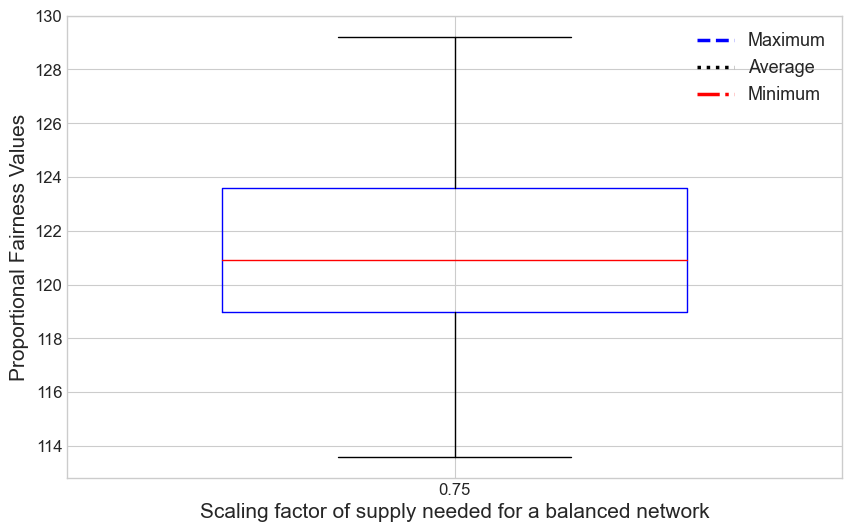

In [6]:
variable_name = 'proportional_fairness'

plt.figure(figsize=(10, 6))

min_values = []
max_values = []
mean_values = []

# Columns to exclude from boxplot computation
exclude_columns = ['mean', 'std', 'min', 'max', 'median', 'mode', 'q1', 'q2', 'q3']

# Iterate over the dictionary of DataFrames
for index, (key, df) in enumerate(data.items(), start=1):
    min_values.append(df[df['var_name'] == variable_name]['min'].iloc[0])
    mean_values.append(df[df['var_name'] == variable_name]['mean'].iloc[0])
    max_values.append(df[df['var_name'] == variable_name]['max'].iloc[0])
    
    filtered_df = df.drop(exclude_columns, axis=1)
    
    # Extract data for the 'proportional_fairness' variable
    variable_data = filtered_df[filtered_df['var_name'] == 'proportional_fairness'].drop('var_name', axis=1).T.squeeze()
    
    # Create a boxplot for the current DataFrame, aligning it based on the index
    plt.boxplot(variable_data, positions=[index], widths=0.6, whis=[0, 100], 
                boxprops=dict(color='blue', linewidth=1), 
                medianprops=dict(color='red', linewidth=1))

# Plot connected lines for min, max, and average
plt.plot(range(1, len(data) + 1), max_values, label='Maximum', linestyle='--', color='blue', linewidth=2.5)
plt.plot(range(1, len(data) + 1), mean_values, label='Average', linestyle=':', color='black', linewidth=2.5)
plt.plot(range(1, len(data) + 1), min_values, label='Minimum', linestyle='-.', color='red', linewidth=2.5)

# Set x-axis labels based on the keys of the dictionary
plt.xticks(range(1, len(data) + 1), data.keys(), fontsize = 12)
plt.xlabel('Scaling factor of supply needed for a balanced network', fontsize = 15)
plt.yticks(fontsize = 12)
plt.legend(fontsize=13)

# Add title and labels
# plt.title('Boxplot for Proportional Fairness by Scarcity Level')
plt.ylabel('Proportional Fairness Values', fontsize = 15)

plt.grid(True)
plt.show()

# Dispersion & Jensen gap maps

Per the latest scope: EEVS/EVPI/VSS are no longer the headline result (kept below,
now marked legacy/lower priority). What matters now is **where the DE solution's
per-node allocation `phi` is most volatile across scenarios**, and **where
Formulation B's ex-post Jensen gap concentrates**.

Instead of the old nested min/Q1/median/Q3/max circle stack (5 circles to compare
by eye per node), each demand node below is colored by a single, directly
comparable metric:

1. **Coefficient of variation** of `phi_i` across the 150 DE scenarios
   (`std/mean` - a standard dispersion measure, 0 = no dispersion).
2. **Ex-post Jensen gap per node**, read straight from
   `results/jensen_gap_expost_from_de.csv` (see `src/jensen_gap_from_de_csv.py` and
   the "Ex-post Jensen gap" cell in `optModels_final.ipynb`).

Supply (diamond) and transshipment (square) nodes are kept for context but carry
no metric (they have no `phi`). Reuses the `x_coord`/`y_coord`/`supply_nodes`/
`transshipment_nodes`/`A_k`/`SVI.png` topology already built earlier in this
notebook.


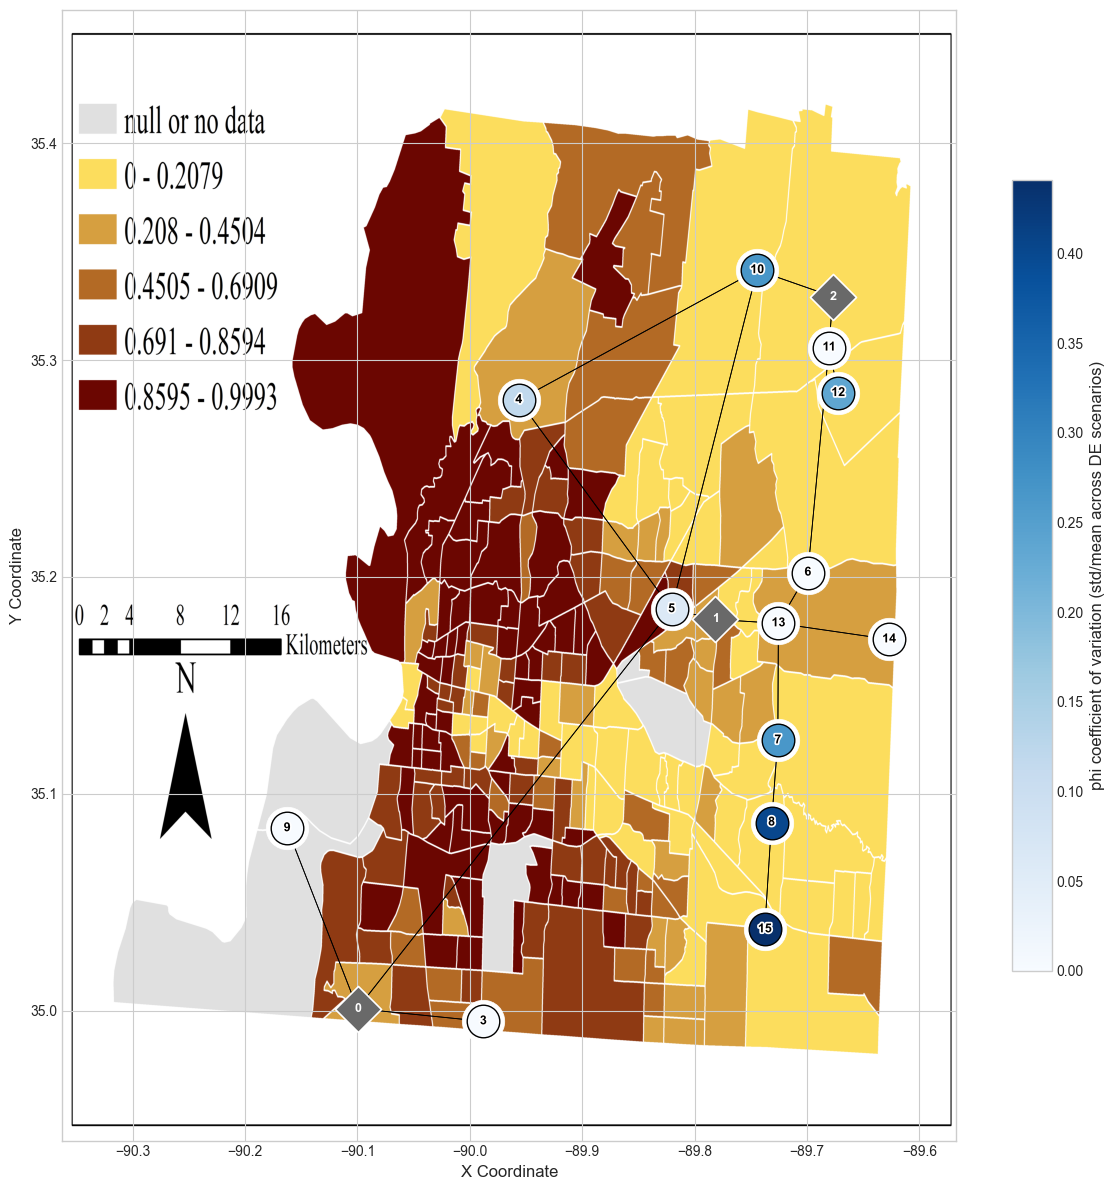

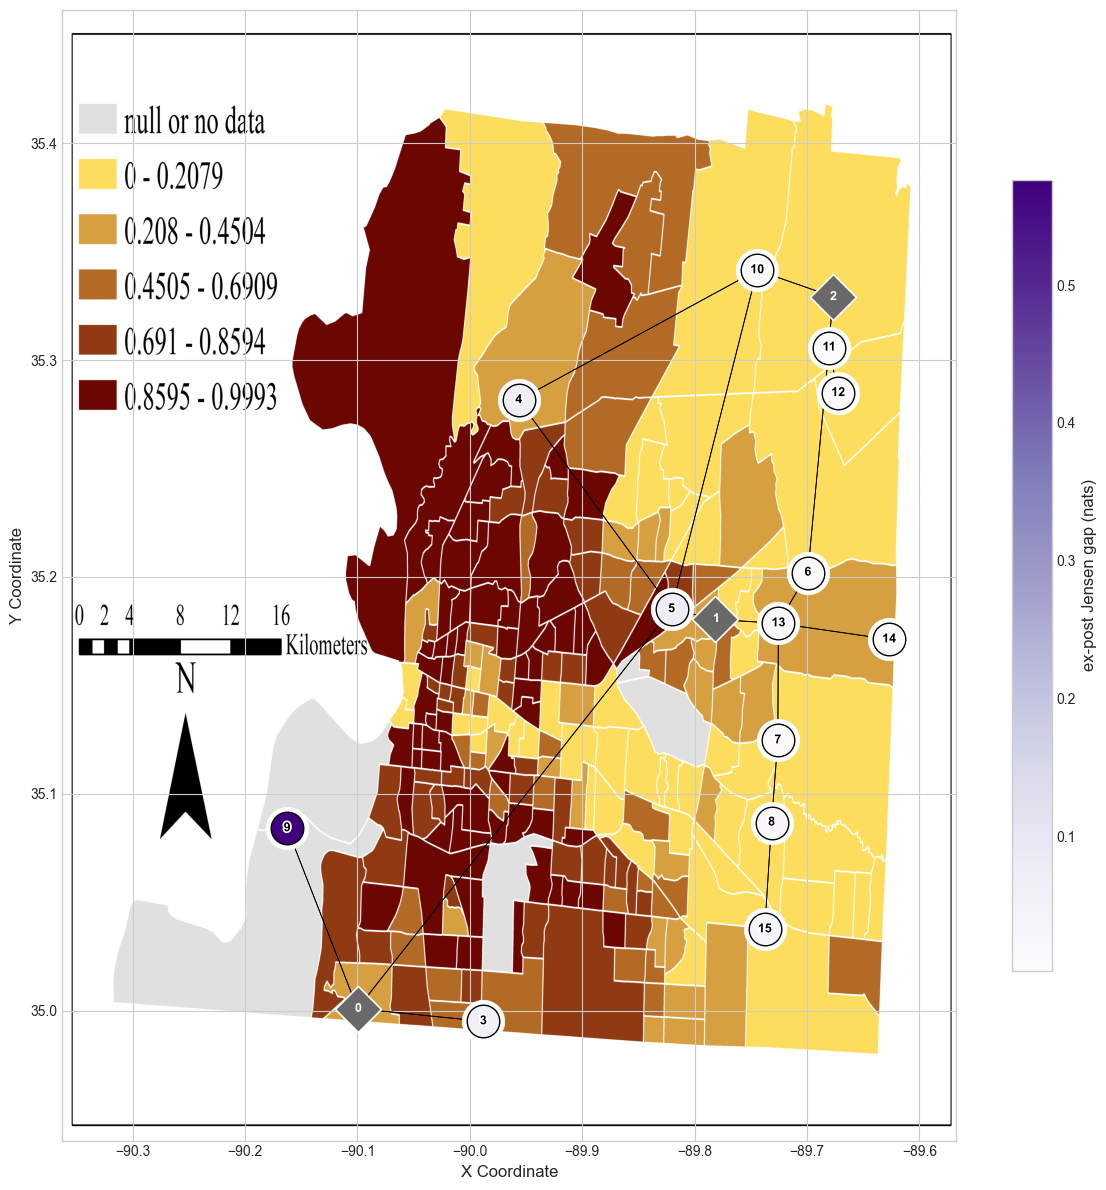

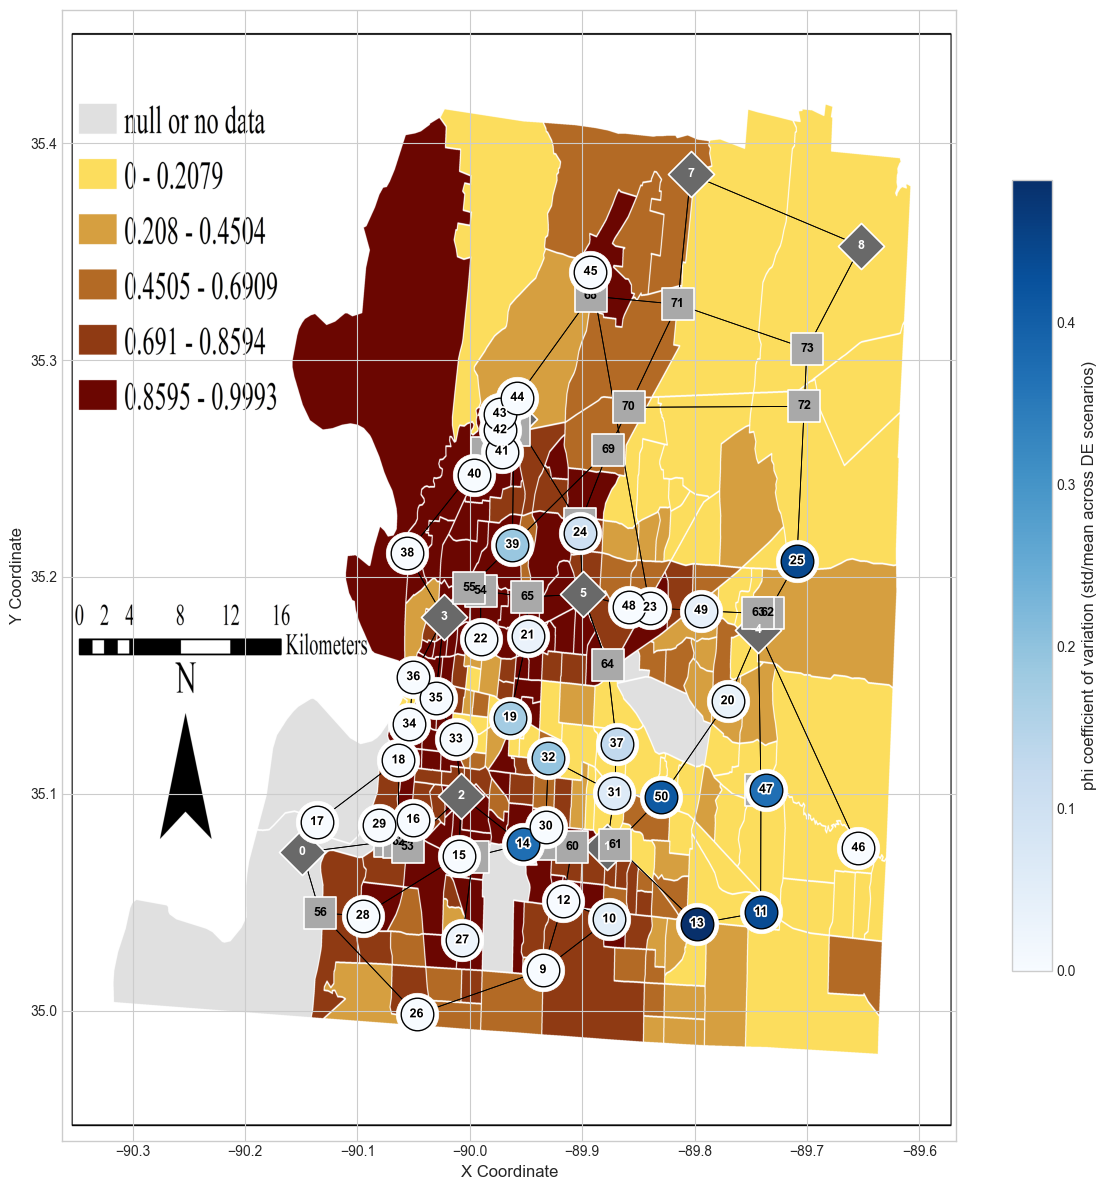

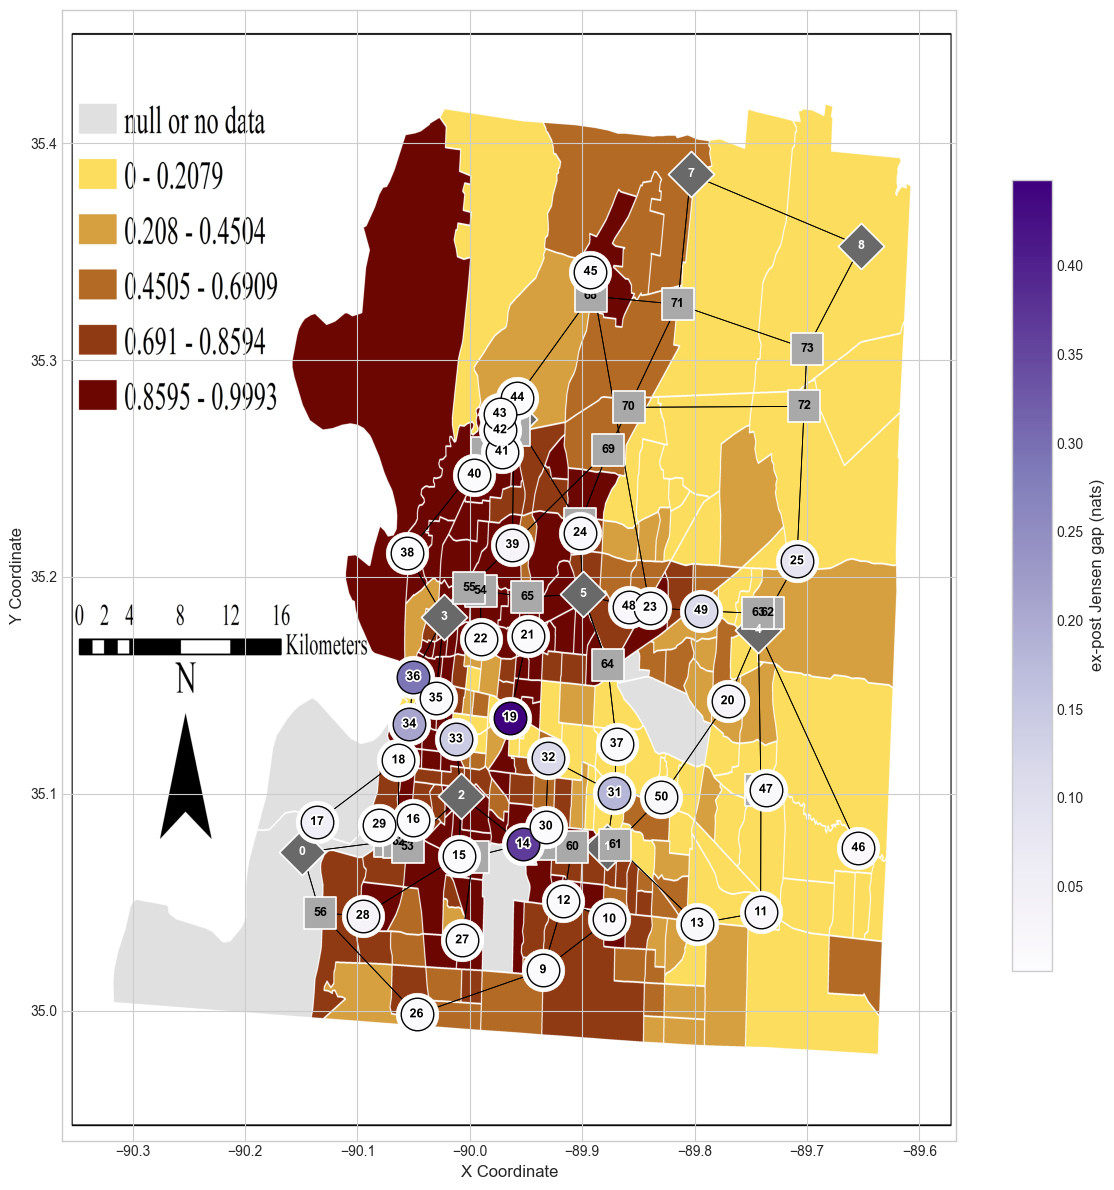

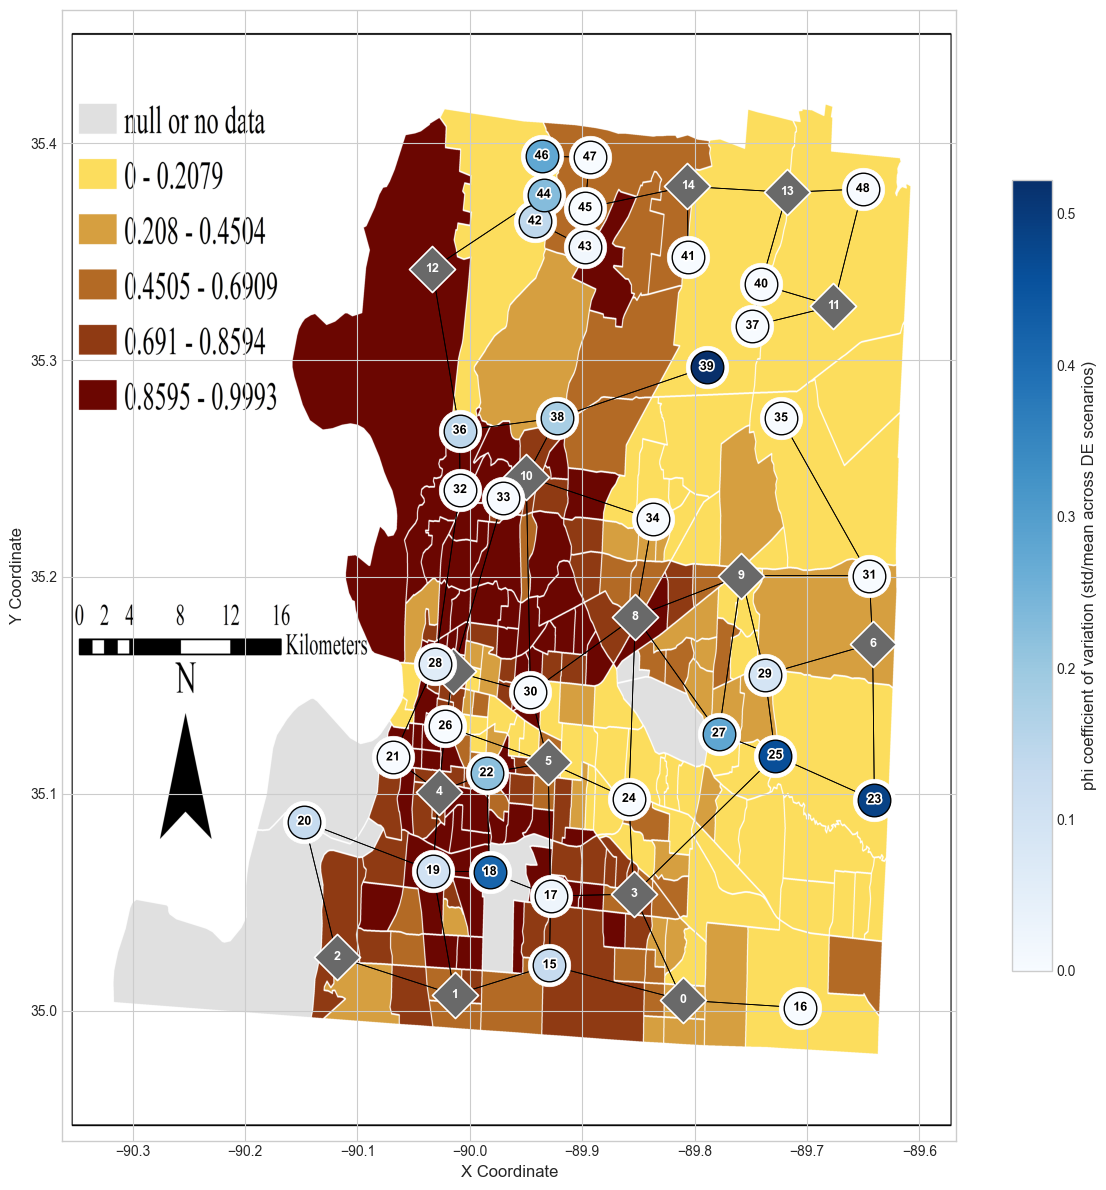

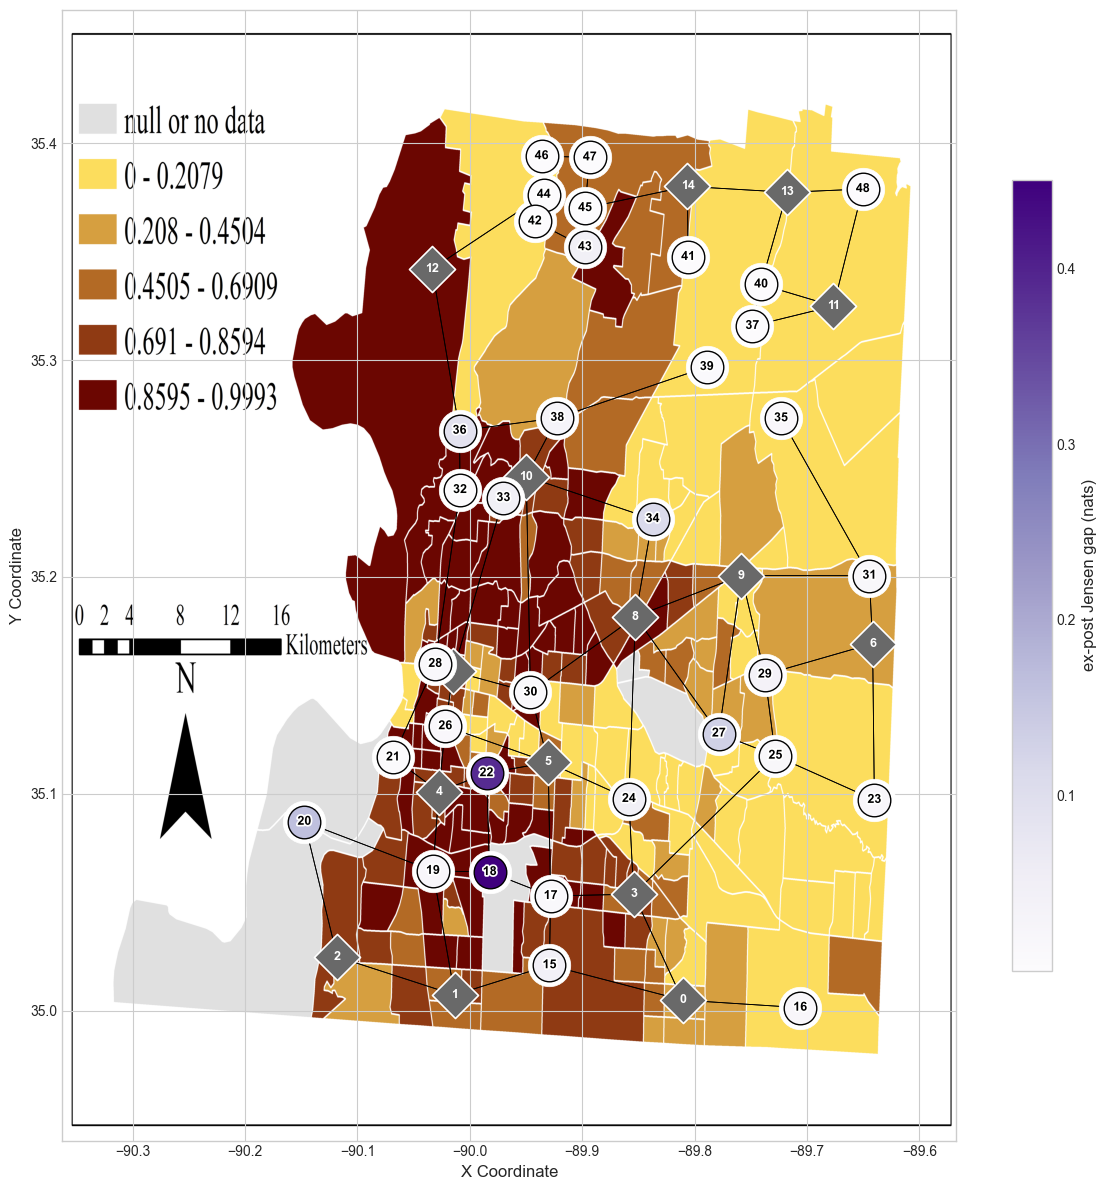

In [7]:
import ast
import glob as _glob
from pathlib import Path
import matplotlib.patheffects as _pe

_RESULTS_DIR = Path('..') / 'results'


def _compute_cv_by_network(de_csv_path):
    """Coefficient of variation (std/mean) of phi_i across DE scenarios, per node."""
    df = pd.read_csv(de_csv_path, index_col=0)
    omega_cols = sorted([c for c in df.columns if c.isdigit()], key=int)
    cv = {'Gas': {}, 'Power': {}, 'Water': {}}
    for idx in df.index:
        if not idx.startswith('phi_('):
            continue
        i, k, l = ast.literal_eval(idx[len('phi_'):])
        if k not in cv:
            continue
        vals = df.loc[idx, omega_cols].astype(float).values
        mean, std = vals.mean(), vals.std()
        cv[k][extract_node_number(i)] = std / mean if mean > 1e-9 else 0.0
    return cv


def _compute_gap_by_network(jensen_csv_path):
    """Per-node ex-post Jensen gap, from jensen_gap_from_de_csv.py's output CSV."""
    jgdf = pd.read_csv(jensen_csv_path)
    gap = {'Gas': {}, 'Power': {}, 'Water': {}}
    for _, row in jgdf.iterrows():
        k = row['network']
        if k in gap:
            gap[k][extract_node_number(row['node'])] = row['node_jensen_gap']
    return gap


def plot_network_metric_map(network, node_values, cbar_label, cmap='Blues', fname=None):
    """Color each demand node on the network map by a single scalar metric
    (e.g. CV or Jensen gap) instead of stacking 5 nested min/Q1/median/Q3/max
    circles - a colorbar communicates dispersion/gap at a glance. No title is
    drawn on the figure itself (see docs/dossier.md Section 13 for what each
    map means); markers are kept smaller with a white halo + outlined labels
    so nearby nodes don't visually merge, and single-hue sequential colormaps
    (Blues/Purples) are used so node markers stay legible against the warm
    yellow/orange/red SVI choropleth background.
    """
    img = mpimg.imread('SVI.png')
    xmin = min(x_coord['Gas'].values()) - 0.2
    xmax = max(x_coord['Gas'].values()) + 0.06
    ymin = min(y_coord['Gas'].values()) - 0.055
    ymax = max(y_coord['Gas'].values()) + 0.12

    fig, ax = plt.subplots(figsize=(12, 12))
    ax.imshow(img, extent=[xmin, xmax, ymin, ymax], aspect='auto')

    vals = list(node_values.values())
    vmin, vmax = (min(vals), max(vals)) if vals else (0, 1)
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    cmap_obj = plt.get_cmap(cmap)

    base_size = 550
    halo_size = base_size * 1.7
    text_outline = [_pe.withStroke(linewidth=2.5, foreground='white')]

    for node in supply_nodes[network]:
        x, y = x_coord[network][node], y_coord[network][node]
        ax.scatter(x, y, marker='D', s=base_size, color='dimgray', edgecolor='white', linewidth=1.2, zorder=3)
        ax.text(x, y, node, fontsize=9, ha='center', va='center', weight='bold', color='white', zorder=4)
    for node in transshipment_nodes[network]:
        x, y = x_coord[network][node], y_coord[network][node]
        ax.scatter(x, y, marker='s', s=base_size, color='darkgray', edgecolor='white', linewidth=1.2, zorder=3)
        ax.text(x, y, node, fontsize=9, ha='center', va='center', weight='bold', color='black', zorder=4)
    for node, val in node_values.items():
        x, y = x_coord[network][node], y_coord[network][node]
        color = cmap_obj(norm(val))
        ax.scatter(x, y, marker='o', s=halo_size, color='white', zorder=4)
        ax.scatter(x, y, marker='o', s=base_size, color=color, edgecolor='black', linewidth=1.0, zorder=5)
        ax.text(x, y, node, fontsize=9, ha='center', va='center', weight='bold', color='black',
                zorder=6, path_effects=text_outline)

    for (a, b) in A_k[network]:
        if a in x_coord[network] and b in x_coord[network]:
            ax.plot([x_coord[network][a], x_coord[network][b]], [y_coord[network][a], y_coord[network][b]],
                     color='black', linewidth=0.6, zorder=2)

    sm = plt.cm.ScalarMappable(cmap=cmap_obj, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, shrink=0.7)
    cbar.set_label(cbar_label, fontsize=12)
    ax.set_xlabel('X Coordinate')
    ax.set_ylabel('Y Coordinate')
    plt.tight_layout()
    if fname:
        fig.savefig(fname, format='png', dpi=150, bbox_inches='tight')
    plt.show()


_de_csv_candidates = sorted(_glob.glob(str(_RESULTS_DIR / 'DE_scarce_*.csv')))
_jensen_csv_path = _RESULTS_DIR / 'jensen_gap_expost_from_de.csv'

if _de_csv_candidates:
    cv_by_network = _compute_cv_by_network(_de_csv_candidates[-1])
    gap_by_network = (_compute_gap_by_network(_jensen_csv_path) if _jensen_csv_path.exists()
                       else {'Gas': {}, 'Power': {}, 'Water': {}})

    for net in ['Gas', 'Power', 'Water']:
        plot_network_metric_map(
            net, cv_by_network[net],
            'phi coefficient of variation (std/mean across DE scenarios)', cmap='Blues',
            fname=str(_RESULTS_DIR / f'{net}_dispersion_cv_map.png'))
        if gap_by_network[net]:
            plot_network_metric_map(
                net, gap_by_network[net],
                'ex-post Jensen gap (nats)', cmap='Purples',
                fname=str(_RESULTS_DIR / f'{net}_jensen_gap_map.png'))
else:
    print('No DE_scarce_*.csv found in ../results - run run_experiments.run_all() first.')


## EEVS / EVPI / VSS (legacy, lower priority)

Kept for completeness, but per current scope these are no longer the headline
result (VSS in particular is very small at scarce=0.75). See the dispersion/Jensen
gap maps above for what we now report.


exp_y_VSS_population: [1.0799619170700019]
exp_y_VSS_sample: [1.0760777662410075]

exp_y_EVPI: [1.335053492764839]



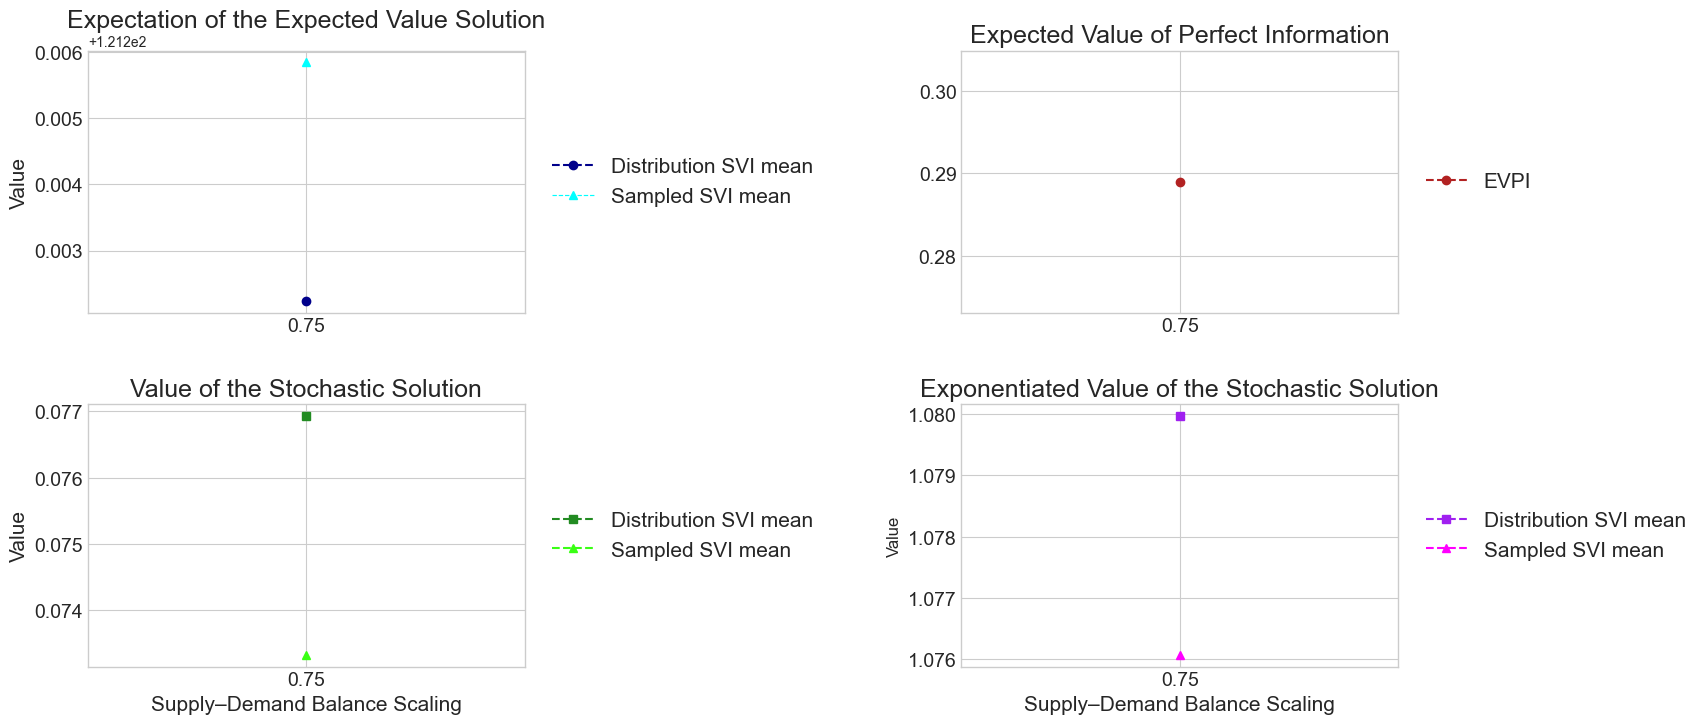

In [8]:
import glob
import json
from pathlib import Path

RESULTS_DIR = Path('..') / 'results'

def _load_summary_stats(results_dir=RESULTS_DIR):
    """Load per-scarcity EEVS/EVPI/VSS straight from the JSON files
    run_experiments.py now writes (scarce_*_summary.json), instead of hand-copying
    numbers out of console output / the .txt summary.
    """
    stats = {}
    for p in sorted(glob.glob(str(results_dir / 'scarce_*_summary.json'))):
        with open(p) as f:
            s = json.load(f)
        stats[s['scarce']] = {
            'EEVS (population mean)': s['OF_EEVS_alpha_mu'],
            'EEVS (sample mean)': s['OF_EEVS_alpha_mu_hat'],
            'EVPI': s['EVPI'],
            'VSS (population mean)': s['VSS_alpha_mu'],
            'VSS (sample mean)': s['VSS_alpha_mu_hat'],
        }
    return stats

summary_stats = _load_summary_stats()
if not summary_stats:
    # Fallback: no scarce_*_summary.json yet (e.g. run_experiments.py hasn't been re-run
    # since the JSON summary was added) - keep the old hand-copied values so this cell
    # still runs, but flag that these are stale.
    print('WARNING: no scarce_*_summary.json found in results/ - falling back to stale, '
          'hand-copied summary_stats. Re-run run_experiments.run_all() to refresh.')
    summary_stats = {0.25:{'EEVS (population mean)':88.86197628636324, 'EEVS (sample mean)':88.87172570430981,'EVPI':0.021685524898671815,'VSS (population mean)':0.26273476466739965, 'VSS (sample mean)':0.25298534672083406},
                     0.50:{'EEVS (population mean)':112.24056810380515, 'EEVS (sample mean)':112.25386204007053,'EVPI':0.023889873581822485,'VSS (population mean)':0.37751793550111756, 'VSS (sample mean)':0.36422399923573323},
                     0.75:{'EEVS (population mean)':121.57491010909611, 'EEVS (sample mean)':121.58303159086249,'EVPI':0.03509987204671461,'VSS (population mean)':0.2793916659544067, 'VSS (sample mean)':0.27127018418802606},
                     1:{'EEVS (population mean)':125.85929106108975, 'EEVS (sample mean)':125.85929106108975,'EVPI':2.9596049273550307e-06,'VSS (population mean)':-2.9530654614973173e-06, 'VSS (sample mean)':-2.9530654614973173e-06}}

# Extracting data for plotting
x = list(summary_stats.keys())
y_EEVS_population = [stats['EEVS (population mean)'] for stats in summary_stats.values()]
y_EEVS_sample = [stats['EEVS (sample mean)'] for stats in summary_stats.values()]
y_EVPI = [stats['EVPI'] for stats in summary_stats.values()]
exp_y_EVPI = [math.exp(stats['EVPI']) for stats in summary_stats.values()]
y_VSS_population = [stats['VSS (population mean)'] for stats in summary_stats.values()]
y_VSS_sample = [stats['VSS (sample mean)'] for stats in summary_stats.values()]

exp_y_VSS_population = [math.exp(stats['VSS (population mean)']) for stats in summary_stats.values()]
exp_y_VSS_sample = [math.exp(stats['VSS (sample mean)']) for stats in summary_stats.values()]

print(f"exp_y_VSS_population: {exp_y_VSS_population}")
print(f"exp_y_VSS_sample: {exp_y_VSS_sample}\n")
print(f"exp_y_EVPI: {exp_y_EVPI}\n")

# --- figure & axes ---
fig, axs = plt.subplots(2, 2, figsize=(20, 8), constrained_layout=False)
(ax1, ax2), (ax3, ax4) = axs

# ax1: EEVS
ax1.plot(x, y_EEVS_population, marker='o', linestyle='--', color='darkblue', label='Distribution SVI mean')
ax1.plot(x, y_EEVS_sample,     marker='^', linestyle='--', color='cyan',      label='Sampled SVI mean', linewidth=0.85)
ax1.set_title('Expectation of the Expected Value Solution', fontsize=18)
ax1.set_ylabel('Value', fontsize=15)
ax1.set_xticks(x)
ax1.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=15)

# ax2: EVPI
ax2.plot(x, y_EVPI, marker='o', linestyle='--', color='firebrick', label='EVPI')
ax2.set_title('Expected Value of Perfect Information', fontsize=18)
ax2.set_xticks(x)
ax2.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=15)

# ax3: VSS
ax3.plot(x, y_VSS_population, marker='s', linestyle='--', color='forestgreen', label='Distribution SVI mean')
ax3.plot(x, y_VSS_sample,     marker='^', linestyle='--', color='#39FF14',     label='Sampled SVI mean')
ax3.set_title('Value of the Stochastic Solution', fontsize=18)
ax3.set_ylabel('Value', fontsize=15)
ax3.set_xlabel('Supply–Demand Balance Scaling', fontsize=15)
ax3.set_xticks(x)
ax3.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=15)
ax3.grid(True)

# ax4: exp(VSS)
ax4.plot(x, exp_y_VSS_population, marker='s', linestyle='--', color='#A020F0', label='Distribution SVI mean')
ax4.plot(x, exp_y_VSS_sample,     marker='^', linestyle='--', color='#FF00FF', label='Sampled SVI mean')
ax4.set_title('Exponentiated Value of the Stochastic Solution', fontsize=18)
ax4.set_ylabel('Value', fontsize=12)
ax4.set_xlabel('Supply–Demand Balance Scaling', fontsize=15)
ax4.set_xticks(x)
ax4.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=15)
ax4.grid(True)

ax1.tick_params(axis='both', labelsize=14)
ax2.tick_params(axis='both', labelsize=14)
ax3.tick_params(axis='both', labelsize=14)
ax4.tick_params(axis='both', labelsize=14)

# give room on the right for the outside legends
plt.subplots_adjust(right=0.78, wspace=1, hspace=0.35)

# Save + show
plt.show()
fig.savefig('summary_stats.pdf', format='pdf', bbox_inches='tight')

In [9]:
# Formulation B: EVPI/VSS with Formulation B's own objective standing in for DE
# (see run_formulation_b_pilot.run_full_case_study docstring for why DE itself doesn't
# have a separate analog for Formulation B). Loaded from
# formulation_b_full_case_study_*_summary.json - no hand-copying needed.
def _load_formulation_b_summaries(results_dir=RESULTS_DIR):
    stats = {}
    for p in sorted(glob.glob(str(results_dir / 'formulation_b_full_case_study_*_summary.json'))):
        with open(p) as f:
            s = json.load(f)
        label = s['network'] if s['network'] else 'all_networks'
        stats[(label, s['scarce'])] = s
    return stats

formulation_b_stats = _load_formulation_b_summaries()

if formulation_b_stats:
    labels = [f"{net}\n(scarce={scarce})" for (net, scarce) in formulation_b_stats.keys()]
    evpi_b = [s['EVPI_B'] for s in formulation_b_stats.values()]
    vss_b = [s['VSS_B'] for s in formulation_b_stats.values()]

    fig_b, (bx1, bx2) = plt.subplots(1, 2, figsize=(14, 5))
    bx1.bar(labels, evpi_b, color='firebrick')
    bx1.set_title('EVPI (Formulation B standing in for DE)', fontsize=14)
    bx1.set_ylabel('OF_WS - OF_B')
    bx1.tick_params(axis='x', rotation=30)

    bx2.bar(labels, vss_b, color='forestgreen')
    bx2.set_title('VSS (Formulation B standing in for DE)', fontsize=14)
    bx2.set_ylabel('OF_B - OF_EEVS (sample mean)')
    bx2.tick_params(axis='x', rotation=30)

    plt.tight_layout()
    plt.show()
    fig_b.savefig('formulation_b_evpi_vss.pdf', format='pdf', bbox_inches='tight')
else:
    print('No formulation_b_full_case_study_*_summary.json files found yet - run '
          'run_formulation_b_pilot.run_full_case_study() first.')


No formulation_b_full_case_study_*_summary.json files found yet - run run_formulation_b_pilot.run_full_case_study() first.


In [10]:
# # Create the figure and axes for 6 subplots arranged in a 6x1 grid
# fig, ax = plt.subplots(6, 1, figsize=(5, 10))

# # Create the outer pie charts for the subplots
# neon_green = [(0.4, 1.0, 0.0)]
# x = ['Demand', 'Maximum', '3rd\nquantile', 'Median', '1st\nquantile', 'Minimum']
# thy_colors = ['white', 'blue', ['#800000'], 'yellow', 'magenta', neon_green, 'red']

# grey_background = '#CCCCCC'
# for i in range(6):
#     outer_pie = ax[i].pie([18], radius=1.5, colors=['k'])
#     ax[i].pie([18], radius=1.475, colors=thy_colors[i])
#     ax[i].set_aspect('equal')
#     ax[i].set_facecolor(grey_background)
#     ax[i].set_ylabel(x[i]+'\n', rotation = 0,fontsize=15)
#     ax[i].yaxis.set_label_coords(1.7, 0.1)  # Adjust label position


# # Adjust spacing between subplots
# plt.subplots_adjust(hspace=0.5)

# # Save the plot as PDF and PNG
# # fig.savefig('results_label.pdf', format='pdf', bbox_inches='tight')
# # fig.savefig('results_label.png', bbox_inches='tight')

# # Show the plot
# plt.show()

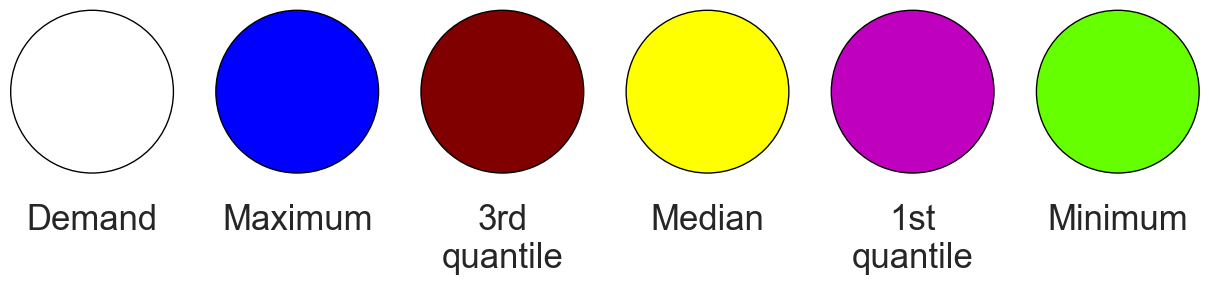

In [11]:
# Create the figure and axes for 6 subplots arranged in a 1x6 grid
fig, ax = plt.subplots(1, 6, figsize=(15, 3))

# Create the outer pie charts for the subplots
neon_green = [(0.4, 1.0, 0.0)]
x = ['Demand', 'Maximum', '3rd\nquantile', 'Median', '1st\nquantile', 'Minimum']
thy_colors = ['white', 'blue', ['#800000'], ['#FFFF00'], 'magenta', neon_green, 'red']

grey_background = '#CCCCCC'
for i in range(6):
    outer_pie = ax[i].pie([18], radius=1.5, colors=['k'])
    ax[i].pie([18], radius=1.475, colors=thy_colors[i])
    ax[i].set_aspect('equal')
    ax[i].set_facecolor(grey_background)
    ax[i].set_xlabel('\n' + x[i], fontsize=25, rotation=0, ha='center')  # Adjust label position

# Adjust spacing between subplots
plt.subplots_adjust(wspace=0.5)

# Save the plot as PDF and PNG
fig.savefig('results_label.pdf', format='pdf', bbox_inches='tight')
# fig.savefig('results_label.png', bbox_inches='tight')

# Show the plot
plt.show()

# Gas

In [12]:
gas_allocation_data = {}

# Iterate over each scarcity level in the data dictionary
for scarcity_level, df in data.items():
    # Apply the function to 'var_name' column to create a new column 'network_name'
    df['network_name'] = df['var_name'].apply(extract_network_name)
    # Apply the function to 'var_name' column to create a new column 'node'
    df['node'] = df['var_name'].apply(extract_node_number)
    df['node'].fillna(-1, inplace=True)
    df['node'] = df['node'].astype(int)
    # Filter rows where the first three characters of 'var_name' are 'phi' and the network name is 'Gas'
    gas_subset = df[(df['var_name'].str[:3] == 'phi') & (df['network_name'] == 'Gas')]
#     gas_subset = df[(df['var_name'].str[:12] == 'utility_of_p') & (df['network_name'] == 'Gas')]

    # Store the subset of data in water_allocation_data dictionary
    gas_allocation_data[scarcity_level] = gas_subset

gas_allocation_data[scarce[0]]
gas_uncertain_coeff_data = {}
for scarcity_level, df in data.items():
    # Apply the function to 'var_name' column to create a new column 'network_name'
    df['network_name'] = df['var_name'].apply(extract_network_name)
    # Apply the function to 'var_name' column to create a new column 'node'
    df['node'] = df['var_name'].apply(extract_node_number)
    df['node'].fillna(-1, inplace=True)
    df['node'] = df['node'].astype(int)
    # Filter rows where the first three characters of 'var_name' are 'phi' and the network name is 'Gas'
    gas_subset = df[(df['var_name'].str[:5] == 'alpha') & (df['network_name'] == 'Gas')]
    # Store the subset of data in water_allocation_data dictionary
    gas_uncertain_coeff_data = gas_subset

In [13]:
# Gas utilities of met demands
# gas_utility_demand_data = {}

# # Iterate over each scarcity level in the data dictionary
# for scarcity_level, df in data.items():
#     # Apply the function to 'var_name' column to create a new column 'network_name'
#     df['network_name'] = df['var_name'].apply(extract_network_name)
#     # Apply the function to 'var_name' column to create a new column 'node'
#     df['node'] = df['var_name'].apply(extract_node_number)
#     df['node'].fillna(-1, inplace=True)
#     df['node'] = df['node'].astype(int)
#     # Filter rows where the first three characters of 'var_name' are 'phi' and the network name is 'Gas'
# #     gas_subset = df[(df['var_name'].str[:3] == 'phi') & (df['network_name'] == 'Gas')]
#     gas_subset = df[(df['var_name'].str[:12] == 'utility_of_d') & (df['network_name'] == 'Gas')]

#     # Store the subset of data in water_allocation_data dictionary
#     gas_utility_demand_data[scarcity_level] = gas_subset

# gas_utility_demand_data[0.25]

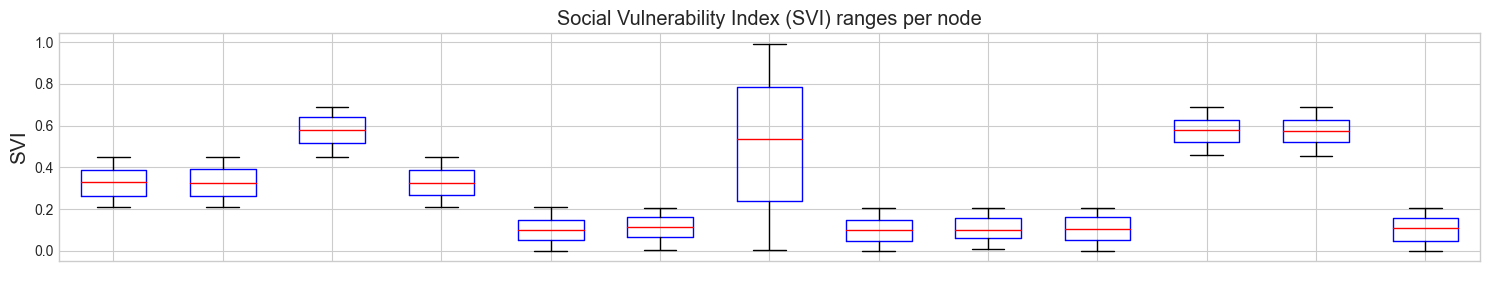

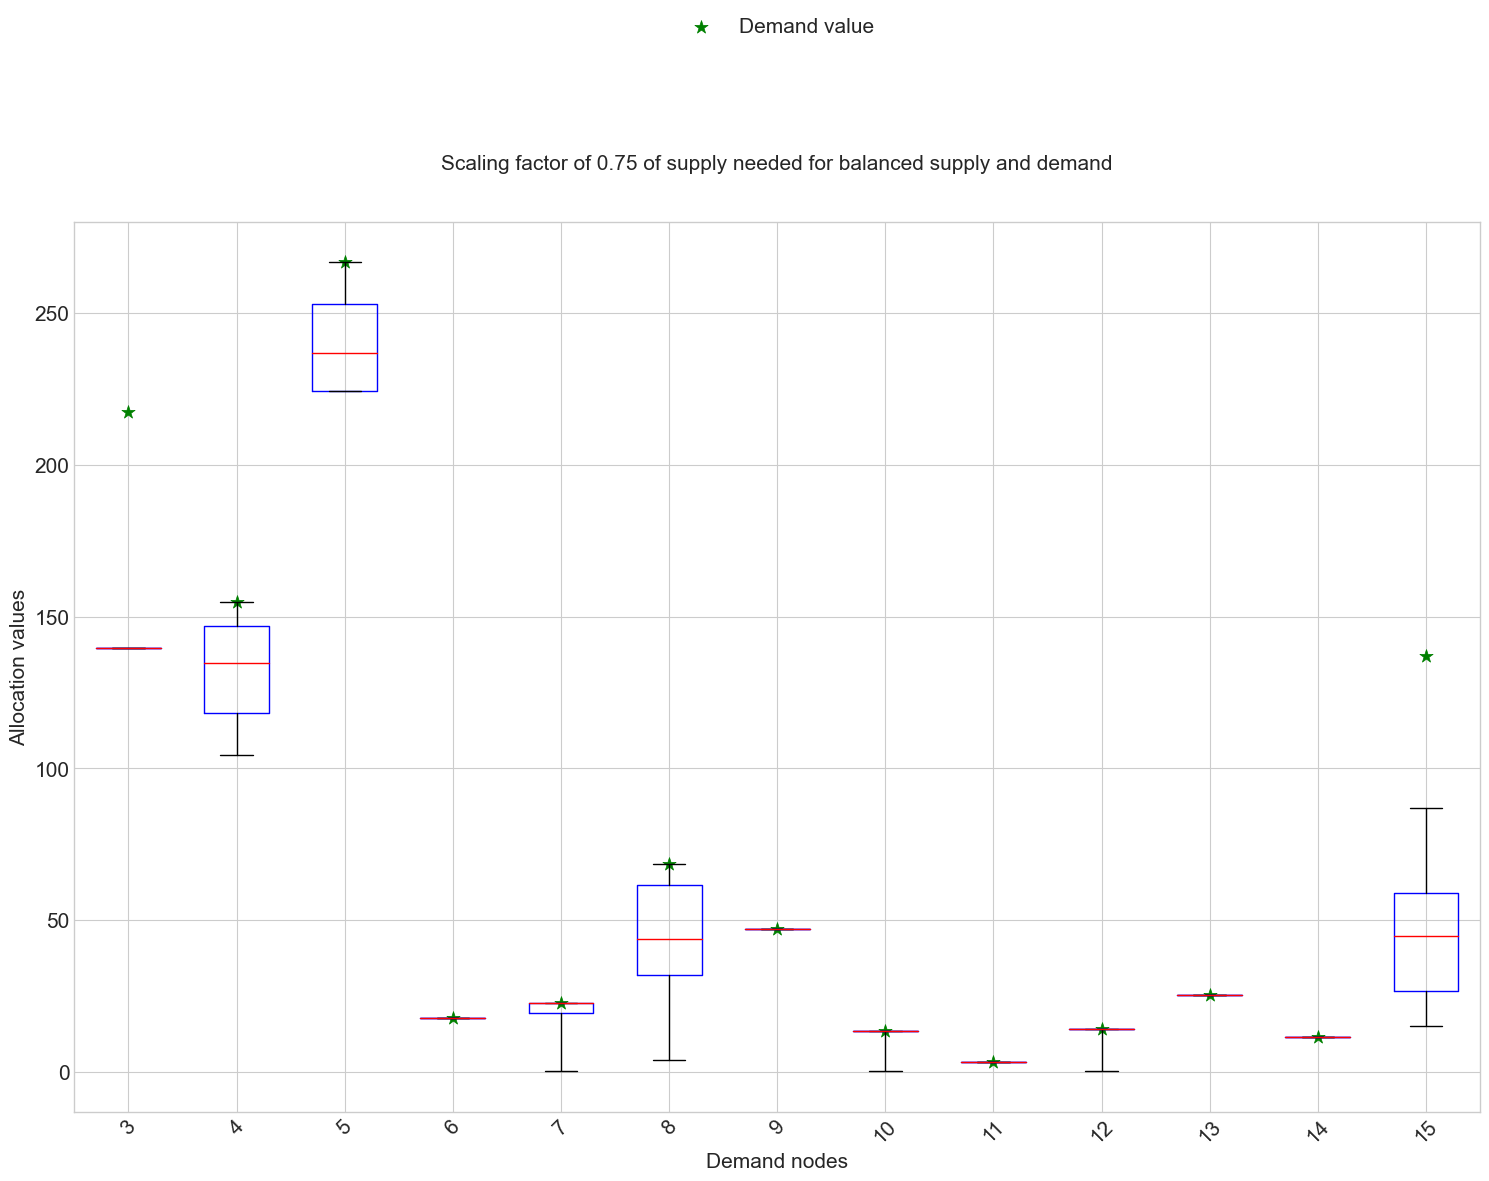

In [14]:
# Columns to exclude from boxplot computation
exclude_columns = ['mean', 'std', 'min', 'max', 'median', 'mode', 'q1', 'q2', 'q3', 'var_name', 'network_name', 'node']

df = gas_uncertain_coeff_data.copy()

plt.figure(figsize=(15, 3))

# Get unique nodes for the current scarcity level
nodes = sorted(df['node'].unique())  # Sort the unique node values
# Update the list of all nodes
all_nodes = []
all_nodes.extend(nodes)
# Prepare data for boxplot
boxplot_data = []
demand_data = []
for node in nodes:
    node_data = df[df['node'] == node].drop(exclude_columns, axis=1)
    boxplot_data.append(node_data.values.flatten())
    demand_data.append(demand['Gas'][node])

# Create boxplot for the current scarcity level
plt.boxplot(boxplot_data, widths=0.6, whis=[0, 100], 
            boxprops=dict(color='blue', linewidth=1), 
            medianprops=dict(color='red', linewidth=1))
plt.title(f'Social Vulnerability Index (SVI) ranges per node')
plt.ylabel('SVI', fontsize = 15)
# plt.tick_params(axis='x', rotation=45)
plt.grid(True)

# Set x ticks and labels only for the bottom subplot
# plt.xlabel('Nodes')
# plt.xticks(range(1, len(all_nodes) + 1))  # Start from 1
plt.xticks(color='white')
plt.tight_layout()
plt.show()

# Determine the number of scarcity levels
num_scarcity_levels = len(gas_allocation_data)

# Create subplots with transposed layout
fig, axes = plt.subplots(num_scarcity_levels, 1, figsize=(15, 12), sharex=True)
axes = np.atleast_1d(axes)  # keep axes indexable when only one scarcity level is present


# Iterate over each scarcity level in the power_allocation_data dictionary
for i, (scarcity_level, df) in enumerate(gas_allocation_data.items()):
    
    # Get unique nodes for the current scarcity level
    nodes = sorted(df['node'].unique())  # Sort the unique node values
    # Update the list of all nodes
    all_nodes = []
    all_nodes.extend(nodes)
    # Prepare data for boxplot
    boxplot_data = []
    demand_data = []
    for node in nodes:
        node_data = df[df['node'] == node].drop(exclude_columns, axis=1)
        boxplot_data.append(node_data.values.flatten())
        demand_data.append(demand['Gas'][node])
    
    # Create boxplot for the current scarcity level
    axes[i].boxplot(boxplot_data, widths=0.6, whis=[0, 100], 
                boxprops=dict(color='blue', linewidth=1), 
                medianprops=dict(color='red', linewidth=1))
    if i == 0:
        # Plot the demand data as scatter points
            axes[i].scatter(range(1,len(nodes)+1), demand_data, s=100, color='g', marker='*', label = 'Demand value')  # Provide x-values (nodes)
    else:
        axes[i].scatter(range(1,len(nodes)+1), demand_data, s=100, color='g', marker='*')  # Provide x-values (nodes)
    axes[i].set_title(f'Scaling factor of {scarcity_level} of supply needed for balanced supply and demand\n\n', fontsize = 15)
    axes[i].set_ylabel('Allocation values', fontsize = 15)
    axes[i].tick_params(axis='y', labelsize=15)

#     axes[i].set_xticklabels(nodes)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].grid(True)

# Set x ticks and labels only for the bottom subplot
axes[-1].set_xlabel('Demand nodes', fontsize = 15)
axes[-1].set_xticks(range(1, len(all_nodes) + 1))  # Start from 1
axes[-1].set_xticklabels(all_nodes, fontsize = 15)
axes[0].legend(fontsize=15, loc = 'upper center', bbox_to_anchor=(0.5,1.25))
plt.tight_layout()
plt.show()

# df = gas_uncertain_coeff_data.copy()

# plt.figure(figsize=(15, 3))

# # Get unique nodes for the current scarcity level
# nodes = sorted(df['node'].unique())  # Sort the unique node values
# # Update the list of all nodes
# all_nodes = []
# all_nodes.extend(nodes)
# # Prepare data for boxplot
# boxplot_data = []
# demand_data = []
# for node in nodes:
#     node_data = df[df['node'] == node].drop(exclude_columns, axis=1)
#     boxplot_data.append(node_data.values.flatten())
#     demand_data.append(demand['Gas'][node])

# # Create boxplot for the current scarcity level
# plt.boxplot(boxplot_data, widths=0.6, whis=[0, 100], 
#             boxprops=dict(color='blue', linewidth=1), 
#             medianprops=dict(color='red', linewidth=1))
# plt.title(f'Social Vulnerability Index (SVI) ranges per node')
# plt.ylabel('SVI', fontsize = 15)
# # plt.tick_params(axis='x', rotation=45)
# plt.grid(True)

# # Set x ticks and labels only for the bottom subplot
# # plt.xlabel('Nodes')
# # plt.xticks(range(1, len(all_nodes) + 1))  # Start from 1
# plt.xticks(color='white')
# plt.tight_layout()
# plt.show()

# # Determine the number of scarcity levels
# num_scarcity_levels = len(gas_allocation_data)

# # Create subplots with transposed layout
# fig, axes = plt.subplots(num_scarcity_levels, 1, figsize=(15, 12), sharex=True)

# # Iterate over each scarcity level in the water_allocation_data dictionary
# for i, (scarcity_level, df) in enumerate(gas_allocation_data.items()):
    
#     # Get unique nodes for the current scarcity level
#     nodes = sorted(df['node'].unique())  # Sort the unique node values
#     # Update the list of all nodes
#     all_nodes = []
#     all_nodes.extend(nodes)
#     # Prepare data for boxplot
#     boxplot_data = []
#     demand_data = []
#     for node in nodes:
#         node_data = df[df['node'] == node].drop(exclude_columns, axis=1)
#         boxplot_data.append(node_data.values.flatten())
#         demand_data.append(demand['Gas'][node])
    
#     # Create boxplot for the current scarcity level
#     axes[i].boxplot(boxplot_data, widths=0.6, whis=[0, 100], 
#                 boxprops=dict(color='blue', linewidth=1), 
#                 medianprops=dict(color='red', linewidth=1))
    
#     if i == 0:
#     # Plot the demand data as scatter points
#         axes[i].scatter(range(1,len(nodes)+1), demand_data, s=100, color='g', marker='*', label = 'Demand value')  # Provide x-values (nodes)
#     else:
#         axes[i].scatter(range(1,len(nodes)+1), demand_data, s=100, color='g', marker='*')  # Provide x-values (nodes)
    
#     # Prepare data for boxplot
# #     nodes = sorted(gas_utility_demand_data[scarcity_level]['node'].unique())
#     nodes = sorted(gas_utility_demand_data[scarcity_level]['node'].unique())
#     boxplot_data = []
#     demand_data = []
#     for node in nodes:
#         node_data = gas_utility_demand_data[scarcity_level][gas_utility_demand_data[scarcity_level]['node'] == node].drop(exclude_columns, axis=1)
#         boxplot_data.append(node_data.values.flatten())
    
# #     axes[i].boxplot(boxplot_data, widths=0.6, whis=[0, 100], 
# #                 boxprops=dict(color='green', linewidth=1), 
# #                 medianprops=dict(color='red', linewidth=1))
    
# #     if i == 0:
# #        # Custom legend patches
# #         box_patch_blue = mpatches.Patch(color='blue', label='Utility of allocations')
# #         box_patch_green = mpatches.Patch(color='green', label='Utility of met demand')

# #         # Adding legend
# #         ax[i].legend(handles=[box_patch_blue, box_patch_green])
    
    
#     axes[i].set_title(f'Scaling factor of {scarcity_level} of supply needed for balanced supply and demand\n\n', fontsize = 15)
#     axes[i].set_ylabel('Allocation values', fontsize = 15)
# #     axes[i].set_ylabel('Utility values', fontsize = 15)
#     axes[i].tick_params(axis='y', labelsize=15)
    
# #     axes[i].set_xticklabels(nodes)
#     axes[i].tick_params(axis='x', rotation=45)
#     axes[i].grid(True)

# # Set x ticks and labels only for the bottom subplot
# axes[-1].set_xlabel('Demand nodes', fontsize = 15)
# axes[-1].set_xticks(range(1, len(all_nodes) + 1))  # Start from 1
# axes[-1].set_xticklabels(all_nodes, fontsize = 15)
# axes[0].legend(fontsize=15, loc = 'upper center', bbox_to_anchor=(0.5,1.25))
# plt.tight_layout()
# plt.show()


------------0.75------------


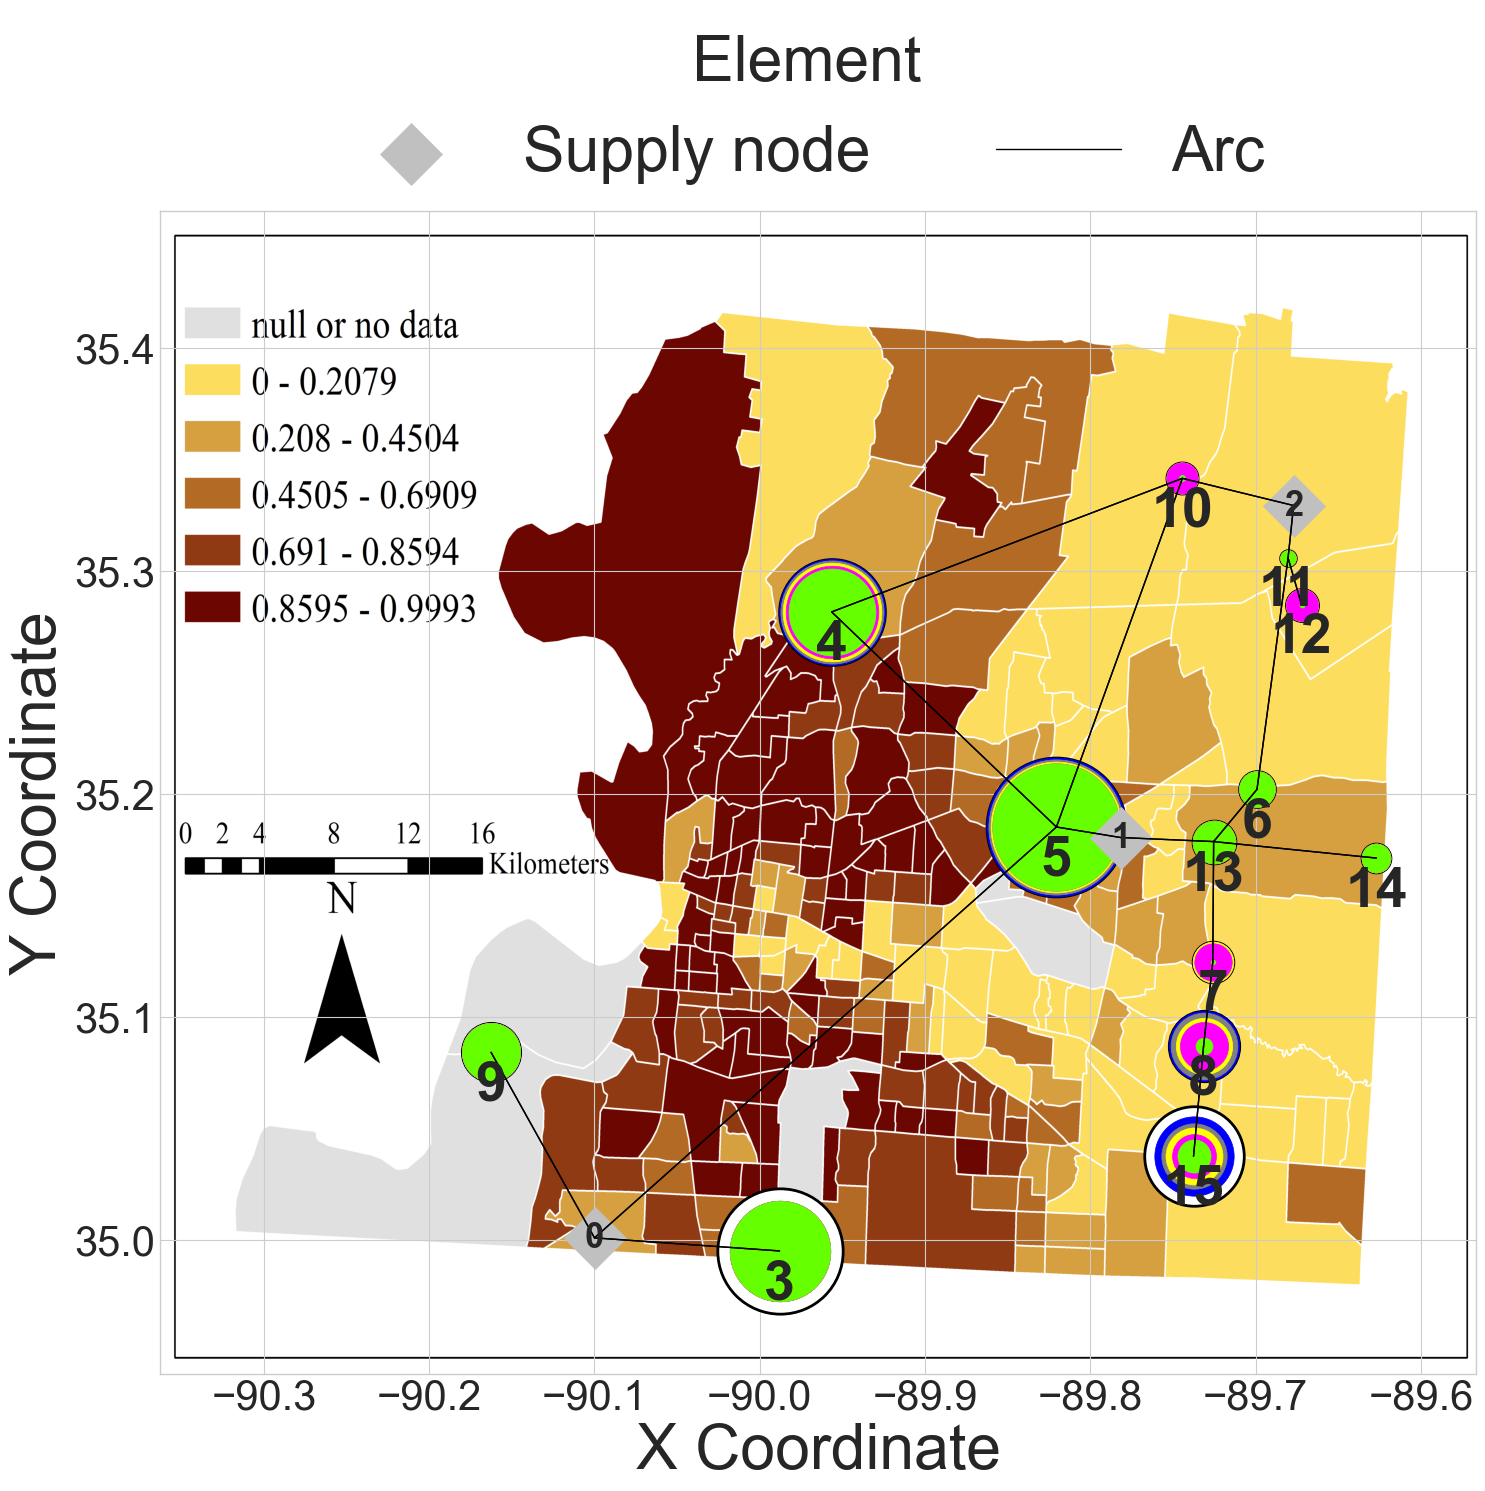

In [15]:
### GAS 

# Load the image
img = mpimg.imread('SVI.png')

xmin = min(x_coord['Gas'].values())-0.2  # Minimum x-coordinate
xmax = max(x_coord['Gas'].values())+0.06  # Maximum x-coordinate
ymin = min(y_coord['Gas'].values())-0.055  # Minimum y-coordinate
ymax = max(y_coord['Gas'].values())+0.12  # Maximum y-coordinate

for scarcity_level in scarce:
    print(f'\n------------{scarcity_level}------------')
    fig, ax = plt.subplots(figsize=(15, 15))
    # Display the image as the background
    ax.imshow(img, extent=[xmin, xmax, ymin, ymax],aspect = 'auto')  # Set the extent based on your data limits
    colors = {'Gas': 'silver', 'Power': '#B2FFB2', 'Water': '#A6D8FF'}
    labels = {'Gas': [], 'Power': [], 'Water': []}
    label_done = {'Gas': {'S':False,'T':False,'D':False}, 'Power': {'S':False,'T':False,'D':False}, 'Water': {'S':False,'T':False,'D':False}}
    thy_size = 1000
    node_type = 'Gas'
    max_demand_value = max_demand[node_type]
    base = 10000
    neon_green = [(0.4, 1.0, 0.0)]
    for number in list(gas_allocation_data[scarcity_level]['node'])+supply_nodes[node_type]+transshipment_nodes[node_type]:

        x = x_coord[node_type][number]
        y = y_coord[node_type][number]
        
        if number in supply_nodes[node_type]:

            if not label_done[node_type]['S']:
                plt.scatter(x, y, marker='D', s=thy_size, color=colors[node_type], label = 'Supply node')
                label_done[node_type]['S'] = True
            else:
                plt.scatter(x, y, marker='D', s=thy_size, color=colors[node_type])

            plt.text(x, y, number, fontsize=25, ha='center', va='center',  weight='bold')

        elif number in transshipment_nodes[node_type]:
            if not label_done[node_type]['T']:
                plt.scatter(x, y, marker='s', s=thy_size, color=colors[node_type], label = 'Transshipment node')
                label_done[node_type]['T'] = True
            else:
                plt.scatter(x, y, marker='s', s=thy_size, color=colors[node_type])

            plt.text(x, y, number, fontsize=25, ha='center', va='center',  weight='bold')

        else:
        
            node_demand = demand[node_type][number]
            max_val = gas_allocation_data[scarcity_level][gas_allocation_data[scarcity_level]['node'] == number]['max']
            Q3 = gas_allocation_data[scarcity_level][gas_allocation_data[scarcity_level]['node'] == number]['q3']
            median = gas_allocation_data[scarcity_level][gas_allocation_data[scarcity_level]['node'] == number]['median']
            Q1 = gas_allocation_data[scarcity_level][gas_allocation_data[scarcity_level]['node'] == number]['q1']
            min_val = gas_allocation_data[scarcity_level][gas_allocation_data[scarcity_level]['node'] == number]['min']
        
#             if not label_done[node_type]['D']:
#                 plt.scatter(x, y, marker='o', edgecolor='k', s= thy_size, facecolor='white', linewidth = 2, label = 'Demand node')
#                 label_done[node_type]['D'] = True
#             else:    

            plt.scatter(x, y, marker='o', edgecolor='k', s= node_demand/max_demand_value*base, facecolor='white', linewidth = 2)
            plt.scatter(x, y, marker='o', s= max_val/max_demand_value*base , color='blue')
            plt.scatter(x, y, marker='o', s= Q3/max_demand_value*base, color='grey')
            plt.scatter(x, y, marker='o', s= median/max_demand_value*base, color='yellow')
            plt.scatter(x, y, marker='o', s= Q1/max_demand_value*base, color='magenta')
            plt.scatter(x, y, marker='o', s= min_val/max_demand_value*base, color=neon_green)
            
            plt.text(x, y-0.015, number, fontsize=40, ha='center', va='center',  weight='bold')


    # Plot lines connecting nodes from list A (in black)
    arc_label = False
    for arc in A_k[node_type]:

        start_node, end_node = arc
        start_x, start_y = x_coord[node_type][start_node], y_coord[node_type][start_node]
        end_x, end_y = x_coord[node_type][end_node], y_coord[node_type][end_node]

        if not arc_label:
            plt.plot([start_x, end_x], [start_y, end_y], linestyle = 'solid', color='black', linewidth = 1, label = 'Arc')
            arc_label = True
        else:
            plt.plot([start_x, end_x], [start_y, end_y], linestyle = 'solid', color='black', linewidth = 1)

    # Show the plot with legend
#     legend = plt.legend(title='Element', bbox_to_anchor=(1.05, 1), loc='upper left', prop={'size': 45}, fontsize = 45)
    legend = plt.legend(title='Element', bbox_to_anchor=(0.1, 1.2), loc='upper left', prop={'size': 45}, fontsize = 45, ncol = 3)
    legend.get_title().set_fontsize(45)

    plt.tick_params(axis='x', labelsize=30)
    plt.xlabel('X Coordinate', fontsize = 45)
    plt.ylabel('Y Coordinate', fontsize = 45)
    plt.tick_params(axis='y', labelsize=30)
    #         plt.title(f"t = {t}, KKT solution", fontsize = 25)

    # Show the plot
    plt.grid(True)
    
#     # Add the saved image to the center bottom of the figure
#     img = plt.imread('results_label.png')
#     # Calculate the position and size of the added image
#     img_height = fig.bbox.height * 0.2  # Adjust the size as needed
#     img_width = img_height * img.shape[1] / img.shape[0]
#     img_x = fig.bbox.width - img_width/0.273
#     img_y = (fig.bbox.y0 + fig.bbox.height)/2 *0.65  # Adjust the vertical position as needed
    
#     # Add the image with adjusted position and size
#     fig.figimage(img, xo=img_x, yo=img_y, origin='upper', alpha=0.8)  # Adjust alpha as needed

    
    # Adjust the layout to ensure everything fits properly
    plt.tight_layout()
    
    fig.savefig(f'{node_type}_network_scarcity_level_{scarcity_level}_dispersion_on_map.pdf', format='pdf', bbox_inches = 'tight')
#     fig.savefig(f'{node_type}_network_scarcity_level_{scarcity_level}_dispersion_on_map.png', bbox_inches = 'tight')
    plt.show()
    

# Power

In [16]:
power_allocation_data = {}

# Iterate over each scarcity level in the data dictionary
for scarcity_level, df in data.items():
    # Apply the function to 'var_name' column to create a new column 'network_name'
    df['network_name'] = df['var_name'].apply(extract_network_name)
    # Apply the function to 'var_name' column to create a new column 'node'
    df['node'] = df['var_name'].apply(extract_node_number)
    df['node'].fillna(-1, inplace=True)
    df['node'] = df['node'].astype(int)
    # Filter rows where the first three characters of 'var_name' are 'phi' and the network name is 'Power'
    power_subset = df[(df['var_name'].str[:3] == 'phi') & (df['network_name'] == 'Power')]

    # Round numeric columns to 6 decimal places
    power_subset = power_subset.round({column: 6 for column in power_subset.columns if column not in ['var_name','network_name']})    
    
    # Store the subset of data in water_allocation_data dictionary
    power_allocation_data[scarcity_level] = power_subset

for scarcity_level, data_frame in power_allocation_data.items():
    df = data_frame.copy()
    df.drop(columns=['var_name','network_name'], inplace=True)
    print(f"Scarcity level: {scarcity_level}")
#     print(df)
    print("\n")
    
    # Check for negative values
    if (df < 0).any().any():
        print(f"Scarcity level {scarcity_level} contains negative values.")
        negative_indices = np.where(df < 0)
        print("Indices and values of negative values:")
        for row, col in zip(*negative_indices):
            print(f"Row: {df.index[row]}, Column: {df.columns[col]}, Value: {df.iloc[row, col]}")
    else:
        print(f"No negative values found in scarcity level {scarcity_level}.")
    print()

power_uncertain_coeff_data = {}
for scarcity_level, df in data.items():
    # Apply the function to 'var_name' column to create a new column 'network_name'
    df['network_name'] = df['var_name'].apply(extract_network_name)
    # Apply the function to 'var_name' column to create a new column 'node'
    df['node'] = df['var_name'].apply(extract_node_number)
    df['node'].fillna(-1, inplace=True)
    df['node'] = df['node'].astype(int)
    # Filter rows where the first three characters of 'var_name' are 'phi' and the network name is 'Gas'
    power_subset = df[(df['var_name'].str[:5] == 'alpha') & (df['network_name'] == 'Power')]
    # Store the subset of data in water_allocation_data dictionary
    power_uncertain_coeff_data = power_subset

Scarcity level: 0.75


No negative values found in scarcity level 0.75.



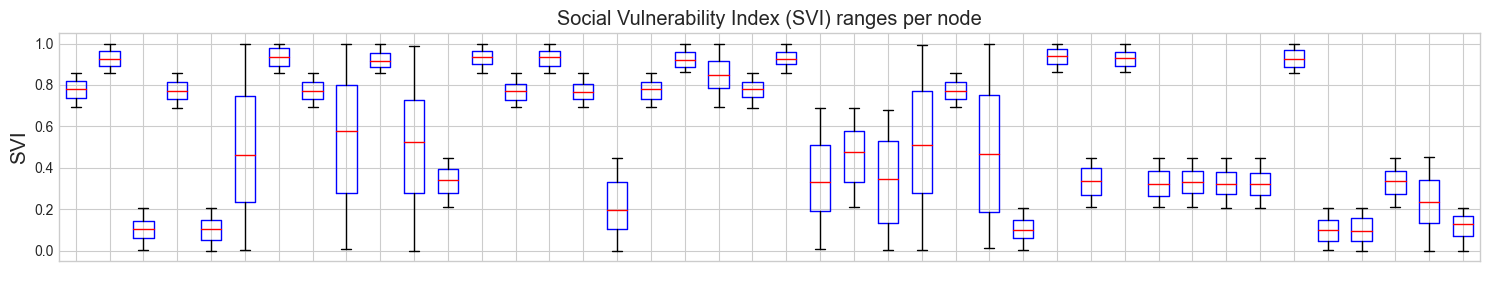

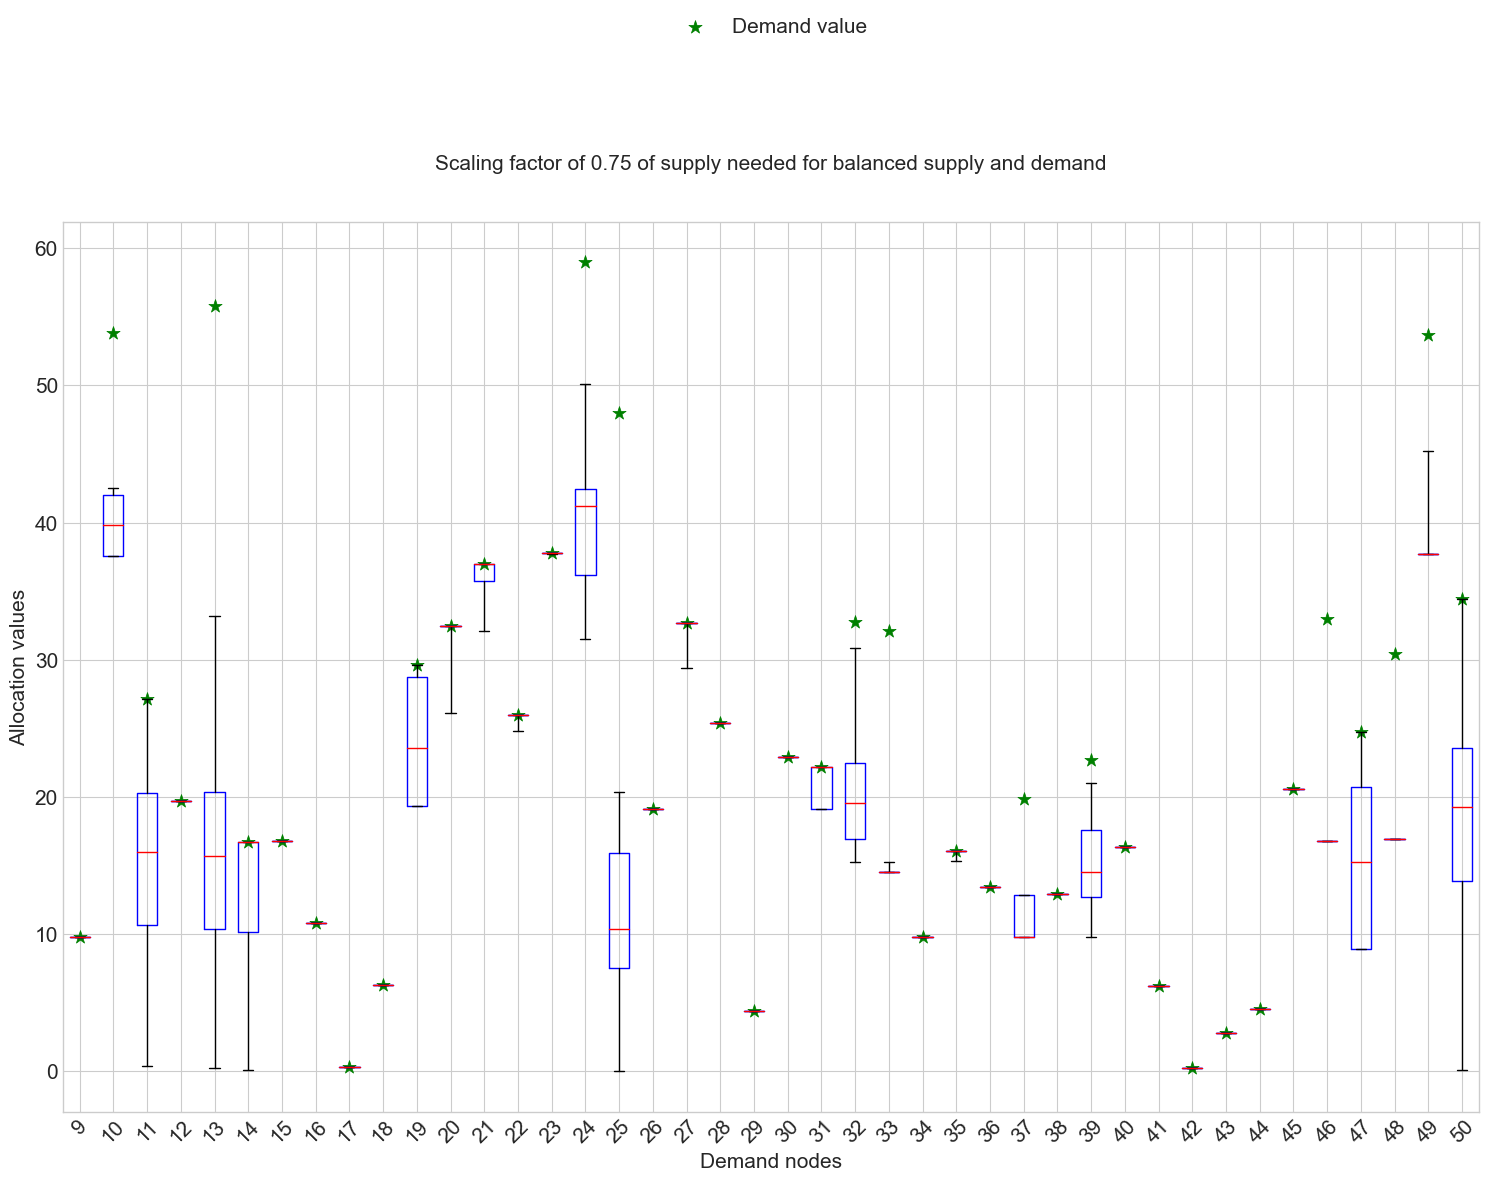

In [17]:

df = power_uncertain_coeff_data.copy()

plt.figure(figsize=(15, 3))

# Get unique nodes for the current scarcity level
nodes = sorted(df['node'].unique())  # Sort the unique node values
# Update the list of all nodes
all_nodes = []
all_nodes.extend(nodes)
# Prepare data for boxplot
boxplot_data = []
demand_data = []
for node in nodes:
    node_data = df[df['node'] == node].drop(exclude_columns, axis=1)
    boxplot_data.append(node_data.values.flatten())
    demand_data.append(demand['Power'][node])

# Create boxplot for the current scarcity level
plt.boxplot(boxplot_data, widths=0.6, whis=[0, 100], 
            boxprops=dict(color='blue', linewidth=1), 
            medianprops=dict(color='red', linewidth=1))
plt.title(f'Social Vulnerability Index (SVI) ranges per node')
plt.ylabel('SVI', fontsize = 15)
# plt.tick_params(axis='x', rotation=45)
plt.grid(True)

# Set x ticks and labels only for the bottom subplot
# plt.xlabel('Nodes')
# plt.xticks(range(1, len(all_nodes) + 1))  # Start from 1
plt.xticks(color='white')
plt.tight_layout()
plt.show()

# Determine the number of scarcity levels
num_scarcity_levels = len(power_allocation_data)

# Create subplots with transposed layout
fig, axes = plt.subplots(num_scarcity_levels, 1, figsize=(15, 12), sharex=True)
axes = np.atleast_1d(axes)  # keep axes indexable when only one scarcity level is present


# Iterate over each scarcity level in the power_allocation_data dictionary
for i, (scarcity_level, df) in enumerate(power_allocation_data.items()):
    
    # Get unique nodes for the current scarcity level
    nodes = sorted(df['node'].unique())  # Sort the unique node values
    # Update the list of all nodes
    all_nodes = []
    all_nodes.extend(nodes)
    # Prepare data for boxplot
    boxplot_data = []
    demand_data = []
    for node in nodes:
        node_data = df[df['node'] == node].drop(exclude_columns, axis=1)
        boxplot_data.append(node_data.values.flatten())
        demand_data.append(demand['Power'][node])
    
    # Create boxplot for the current scarcity level
    axes[i].boxplot(boxplot_data, widths=0.6, whis=[0, 100], 
                boxprops=dict(color='blue', linewidth=1), 
                medianprops=dict(color='red', linewidth=1))
    if i == 0:
        # Plot the demand data as scatter points
            axes[i].scatter(range(1,len(nodes)+1), demand_data, s=100, color='g', marker='*', label = 'Demand value')  # Provide x-values (nodes)
    else:
        axes[i].scatter(range(1,len(nodes)+1), demand_data, s=100, color='g', marker='*')  # Provide x-values (nodes)
    axes[i].set_title(f'Scaling factor of {scarcity_level} of supply needed for balanced supply and demand\n\n', fontsize = 15)
    axes[i].set_ylabel('Allocation values', fontsize = 15)
    axes[i].tick_params(axis='y', labelsize=15)

#     axes[i].set_xticklabels(nodes)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].grid(True)

# Set x ticks and labels only for the bottom subplot
axes[-1].set_xlabel('Demand nodes', fontsize = 15)
axes[-1].set_xticks(range(1, len(all_nodes) + 1))  # Start from 1
axes[-1].set_xticklabels(all_nodes, fontsize = 15)
axes[0].legend(fontsize=15, loc = 'upper center', bbox_to_anchor=(0.5,1.25))
plt.tight_layout()
plt.show()


------------0.75------------


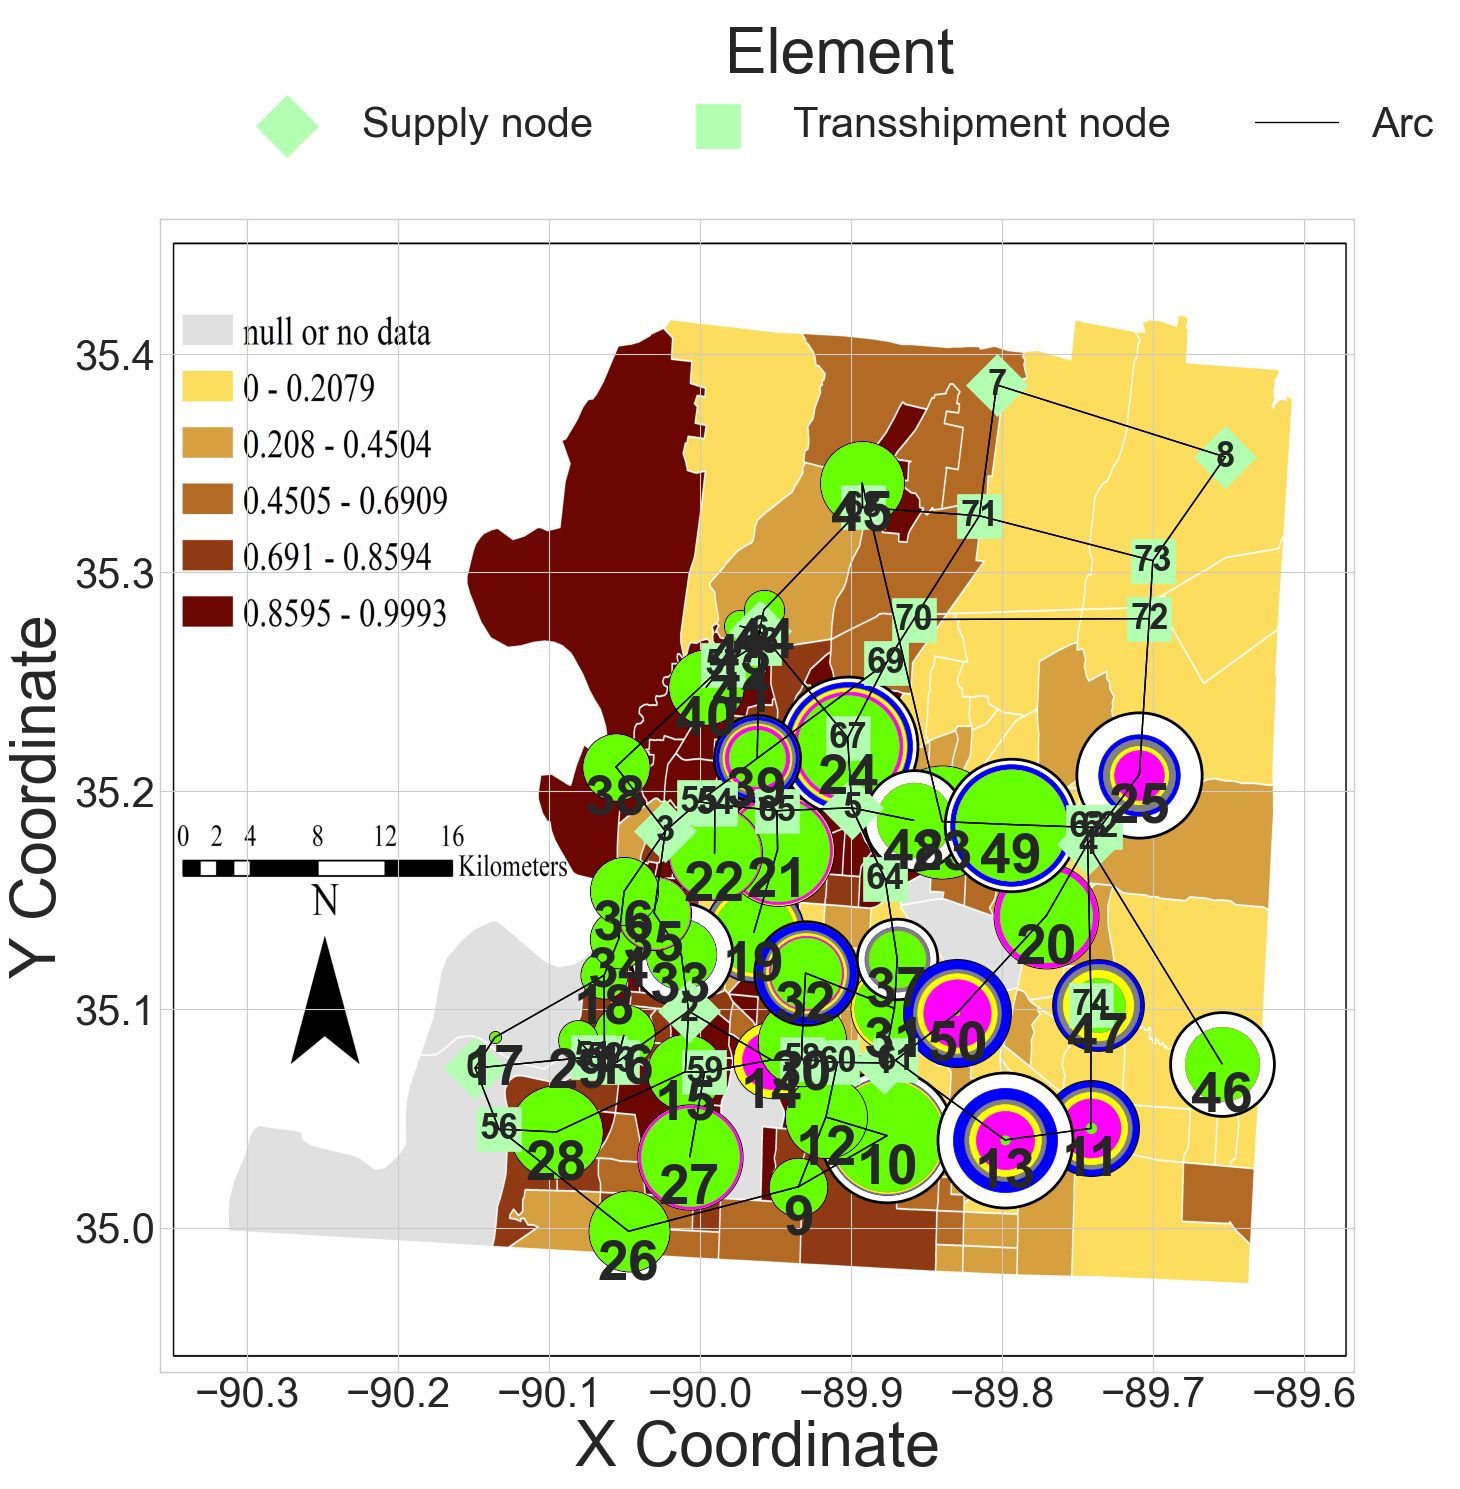

In [18]:
#POWER


xmin = min(x_coord['Gas'].values())-0.195  # Minimum x-coordinate
xmax = max(x_coord['Gas'].values())+0.06  # Maximum x-coordinate
ymin = min(y_coord['Gas'].values())-0.061  # Minimum y-coordinate
ymax = max(y_coord['Gas'].values())+0.12  # Maximum y-coordinate

for scarcity_level in scarce:
    print(f'\n------------{scarcity_level}------------')
    fig, ax = plt.subplots(figsize=(15, 15))
    # Display the image as the background
    ax.imshow(img, extent=[xmin, xmax, ymin, ymax],aspect = 'auto')  # Set the extent based on your data limits
    colors = {'Gas': 'silver', 'Power': '#B2FFB2', 'Water': '#A6D8FF'}
    labels = {'Gas': [], 'Power': [], 'Water': []}
    label_done = {'Gas': {'S':False,'T':False,'D':False}, 'Power': {'S':False,'T':False,'D':False}, 'Water': {'S':False,'T':False,'D':False}}
    thy_size = 1000
    node_type = 'Power'
    max_demand_value = max_demand[node_type]
    base = 10000
    neon_green = [(0.4, 1.0, 0.0)]
    for number in list(power_allocation_data[scarcity_level]['node'])+supply_nodes[node_type]+transshipment_nodes[node_type]:

        x = x_coord[node_type][number]
        y = y_coord[node_type][number]
        
        if number in supply_nodes[node_type]:

            if not label_done[node_type]['S']:
                plt.scatter(x, y, marker='D', s=thy_size, color=colors[node_type], label = 'Supply node')
                label_done[node_type]['S'] = True
            else:
                plt.scatter(x, y, marker='D', s=thy_size, color=colors[node_type])

            plt.text(x, y, number, fontsize=25, ha='center', va='center',  weight='bold')

        elif number in transshipment_nodes[node_type]:
            if not label_done[node_type]['T']:
                plt.scatter(x, y, marker='s', s=thy_size, color=colors[node_type], label = 'Transshipment node')
                label_done[node_type]['T'] = True
            else:
                plt.scatter(x, y, marker='s', s=thy_size, color=colors[node_type])

            plt.text(x, y, number, fontsize=25, ha='center', va='center',  weight='bold')

        else:
        
            node_demand = demand[node_type][number]
            max_val = power_allocation_data[scarcity_level][power_allocation_data[scarcity_level]['node'] == number]['max']
            Q3 = power_allocation_data[scarcity_level][power_allocation_data[scarcity_level]['node'] == number]['q3']
            median = power_allocation_data[scarcity_level][power_allocation_data[scarcity_level]['node'] == number]['median']
            Q1 = power_allocation_data[scarcity_level][power_allocation_data[scarcity_level]['node'] == number]['q1']
            min_val = power_allocation_data[scarcity_level][power_allocation_data[scarcity_level]['node'] == number]['min']
        
#             if not label_done[node_type]['D']:
#                 plt.scatter(x, y, marker='o', edgecolor='k', s= thy_size, facecolor='white', linewidth = 2, label = 'Demand node')
#                 label_done[node_type]['D'] = True
#             else:    

            plt.scatter(x, y, marker='o', edgecolor='k', s= node_demand/max_demand_value*base, facecolor='white', linewidth = 2)
            plt.scatter(x, y, marker='o', s= max_val/max_demand_value*base , color='blue')
            plt.scatter(x, y, marker='o', s= Q3/max_demand_value*base, color='grey')
            plt.scatter(x, y, marker='o', s= median/max_demand_value*base, color='yellow')
            plt.scatter(x, y, marker='o', s= Q1/max_demand_value*base, color='magenta')
            plt.scatter(x, y, marker='o', s= min_val/max_demand_value*base, color=neon_green)
            
            plt.text(x, y-0.015, number, fontsize=40, ha='center', va='center',  weight='bold')


    # Plot lines connecting nodes from list A (in black)
    arc_label = False
    for arc in A_k[node_type]:

        start_node, end_node = arc
        start_x, start_y = x_coord[node_type][start_node], y_coord[node_type][start_node]
        end_x, end_y = x_coord[node_type][end_node], y_coord[node_type][end_node]

        if not arc_label:
            plt.plot([start_x, end_x], [start_y, end_y], linestyle = 'solid', color='black', linewidth = 1, label = 'Arc')
            arc_label = True
        else:
            plt.plot([start_x, end_x], [start_y, end_y], linestyle = 'solid', color='black', linewidth = 1)

    # Show the plot with legend
#     legend = plt.legend(title='Element', bbox_to_anchor=(1.05, 1), loc='upper left', prop={'size': 45}, fontsize = 45)
    legend = plt.legend(title='Element', bbox_to_anchor=(0.04, 1.2), loc='upper left', prop={'size': 30}, fontsize = 45, ncol = 3)
    legend.get_title().set_fontsize(45)

    plt.tick_params(axis='x', labelsize=30)
    plt.xlabel('X Coordinate', fontsize = 45)
    plt.ylabel('Y Coordinate', fontsize = 45)
    plt.tick_params(axis='y', labelsize=30)
    #         plt.title(f"t = {t}, KKT solution", fontsize = 25)

    # Show the plot
    plt.grid(True)
    
#     # Add the saved image to the center bottom of the figure
#     img = plt.imread('results_label.png')
#     # Calculate the position and size of the added image
#     img_height = fig.bbox.height * 0.2  # Adjust the size as needed
#     img_width = img_height * img.shape[1] / img.shape[0]
#     img_x = fig.bbox.width - img_width/0.273
#     img_y = (fig.bbox.y0 + fig.bbox.height)/2 *0.65  # Adjust the vertical position as needed
    
#     # Add the image with adjusted position and size
#     fig.figimage(img, xo=img_x, yo=img_y, origin='upper', alpha=0.8)  # Adjust alpha as needed

    
    # Adjust the layout to ensure everything fits properly
    plt.tight_layout()
    
    fig.savefig(f'{node_type}_network_scarcity_level_{scarcity_level}_dispersion_on_map.pdf', format='pdf', bbox_inches = 'tight')
#     fig.savefig(f'{node_type}_network_scarcity_level_{scarcity_level}_dispersion_on_map.png', bbox_inches = 'tight')
    plt.show()
    

# Water

In [19]:
water_allocation_data = {}

# Iterate over each scarcity level in the data dictionary
for scarcity_level, df in data.items():
    # Apply the function to 'var_name' column to create a new column 'network_name'
    df['network_name'] = df['var_name'].apply(extract_network_name)
    # Apply the function to 'var_name' column to create a new column 'node'
    df['node'] = df['var_name'].apply(extract_node_number)
    df['node'].fillna(-1, inplace=True)
    df['node'] = df['node'].astype(int)
    # Filter rows where the first three characters of 'var_name' are 'phi' and the network name is 'Water'
    water_subset = df[(df['var_name'].str[:3] == 'phi') & (df['network_name'] == 'Water')]
    # Round numeric columns to 6 decimal places
    water_subset = water_subset.round({column: 6 for column in water_subset.columns if column not in ['var_name','network_name']})
    # Store the subset of data in water_allocation_data dictionary
    water_allocation_data[scarcity_level] = water_subset
    
water_uncertain_coeff_data = {}
for scarcity_level, df in data.items():
    # Apply the function to 'var_name' column to create a new column 'network_name'
    df['network_name'] = df['var_name'].apply(extract_network_name)
    # Apply the function to 'var_name' column to create a new column 'node'
    df['node'] = df['var_name'].apply(extract_node_number)
    df['node'].fillna(-1, inplace=True)
    df['node'] = df['node'].astype(int)
    # Filter rows where the first three characters of 'var_name' are 'phi' and the network name is 'Gas'
    water_subset = df[(df['var_name'].str[:5] == 'alpha') & (df['network_name'] == 'Water')]
    # Store the subset of data in water_allocation_data dictionary
    water_uncertain_coeff_data = water_subset

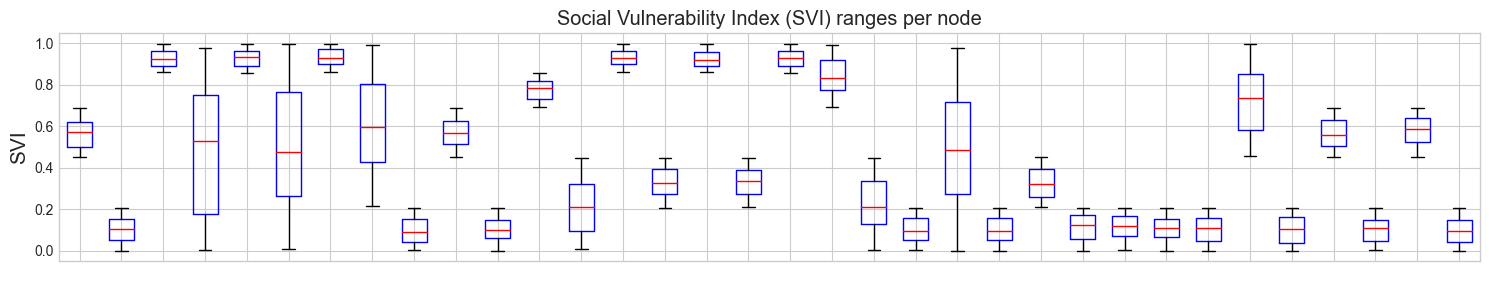

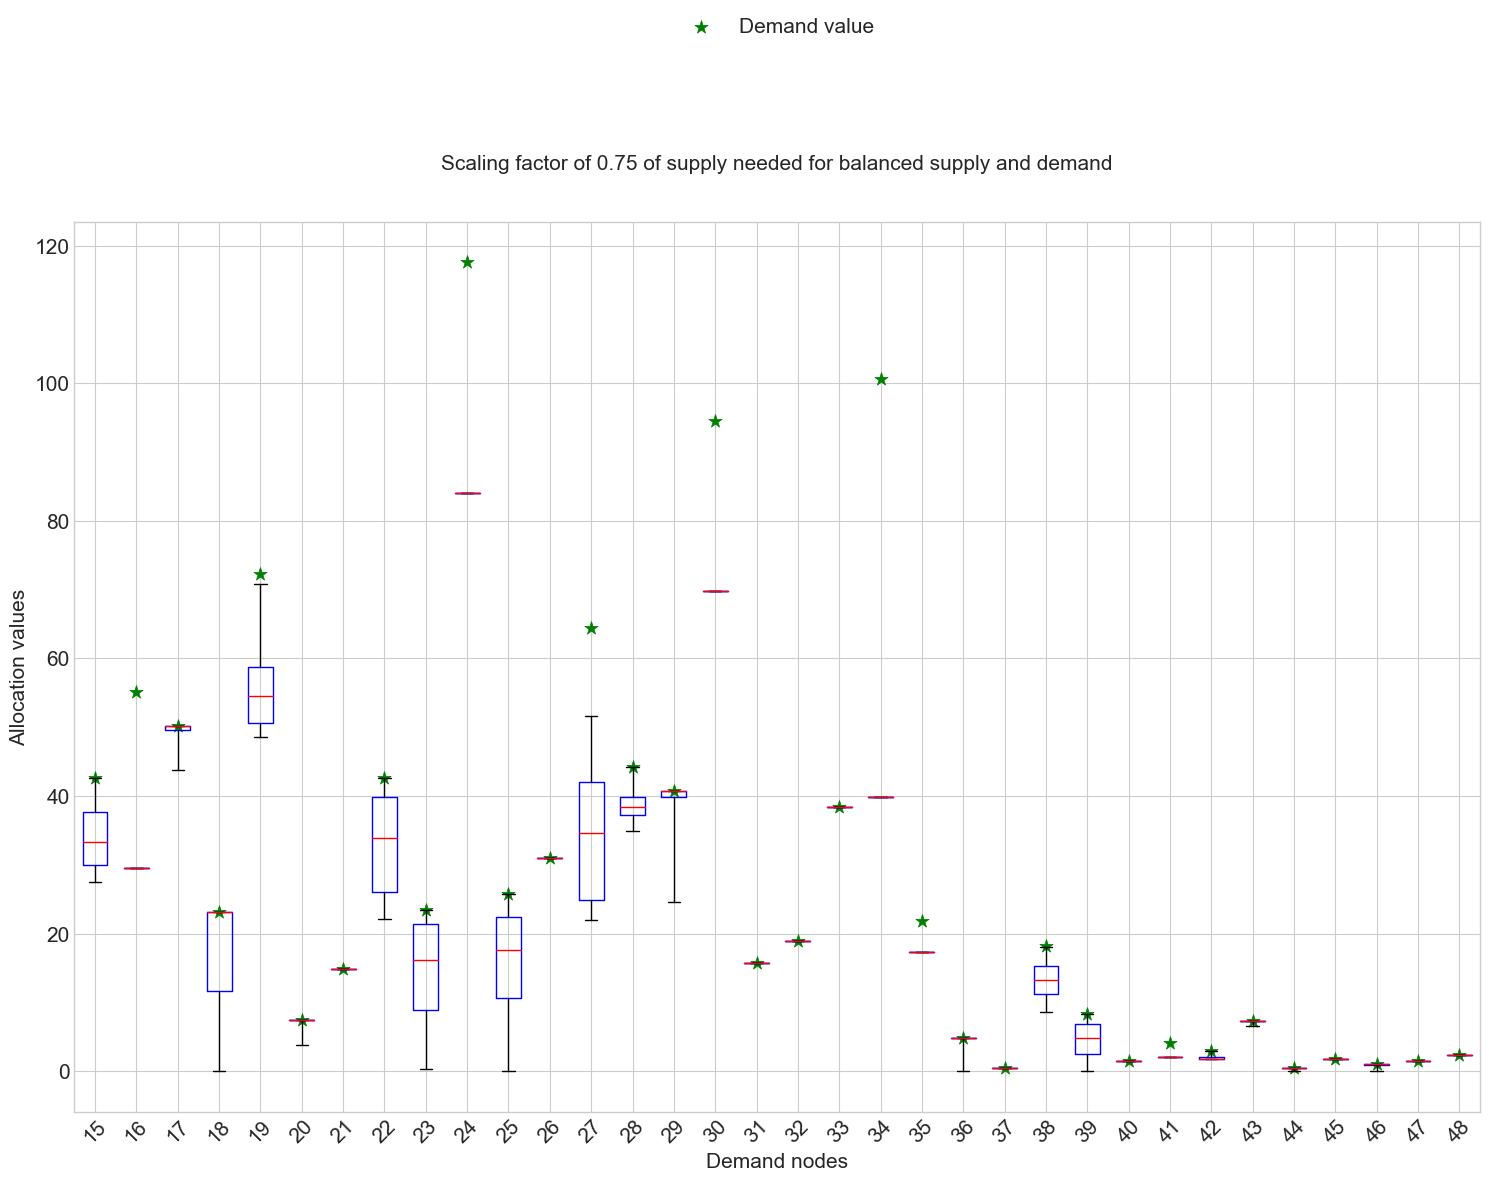

In [20]:
df = water_uncertain_coeff_data.copy()

plt.figure(figsize=(15, 3))

# Get unique nodes for the current scarcity level
nodes = sorted(df['node'].unique())  # Sort the unique node values
# Update the list of all nodes
all_nodes = []
all_nodes.extend(nodes)
# Prepare data for boxplot
boxplot_data = []
demand_data = []
for node in nodes:
    node_data = df[df['node'] == node].drop(exclude_columns, axis=1)
    boxplot_data.append(node_data.values.flatten())
    demand_data.append(demand['Water'][node])

# Create boxplot for the current scarcity level
plt.boxplot(boxplot_data, widths=0.6, whis=[0, 100], 
            boxprops=dict(color='blue', linewidth=1), 
            medianprops=dict(color='red', linewidth=1))
plt.title(f'Social Vulnerability Index (SVI) ranges per node')
plt.ylabel('SVI', fontsize = 15)
# plt.tick_params(axis='x', rotation=45)
plt.grid(True)

# Set x ticks and labels only for the bottom subplot
# plt.xlabel('Nodes')
# plt.xticks(range(1, len(all_nodes) + 1))  # Start from 1
plt.xticks(color='white')
plt.tight_layout()
plt.show()

# Determine the number of scarcity levels
num_scarcity_levels = len(water_allocation_data)

# Create subplots with transposed layout
fig, axes = plt.subplots(num_scarcity_levels, 1, figsize=(15, 12), sharex=True)
axes = np.atleast_1d(axes)  # keep axes indexable when only one scarcity level is present

# Iterate over each scarcity level in the water_allocation_data dictionary
for i, (scarcity_level, df) in enumerate(water_allocation_data.items()):
    
    # Get unique nodes for the current scarcity level
    nodes = sorted(df['node'].unique())  # Sort the unique node values
    # Update the list of all nodes
    all_nodes = []
    all_nodes.extend(nodes)
    # Prepare data for boxplot
    boxplot_data = []
    demand_data = []
    for node in nodes:
        node_data = df[df['node'] == node].drop(exclude_columns, axis=1)
        boxplot_data.append(node_data.values.flatten())
        demand_data.append(demand['Water'][node])
    
    # Create boxplot for the current scarcity level
    axes[i].boxplot(boxplot_data, widths=0.6, whis=[0, 100], 
                boxprops=dict(color='blue', linewidth=1), 
                medianprops=dict(color='red', linewidth=1))
    if i == 0:
        # Plot the demand data as scatter points
            axes[i].scatter(range(1,len(nodes)+1), demand_data, s=100, color='g', marker='*', label = 'Demand value')  # Provide x-values (nodes)
    else:
        axes[i].scatter(range(1,len(nodes)+1), demand_data, s=100, color='g', marker='*')  # Provide x-values (nodes)
    axes[i].set_title(f'Scaling factor of {scarcity_level} of supply needed for balanced supply and demand\n\n', fontsize = 15)
    axes[i].set_ylabel('Allocation values', fontsize = 15)
    axes[i].tick_params(axis='y', labelsize=15)

#     axes[i].set_xticklabels(nodes)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].grid(True)

# Set x ticks and labels only for the bottom subplot
axes[-1].set_xlabel('Demand nodes', fontsize = 15)
axes[-1].set_xticks(range(1, len(all_nodes) + 1))  # Start from 1
axes[-1].set_xticklabels(all_nodes, fontsize = 15)
axes[0].legend(fontsize=15, loc = 'upper center', bbox_to_anchor=(0.5,1.25))
plt.tight_layout()
plt.show()


------------0.75------------


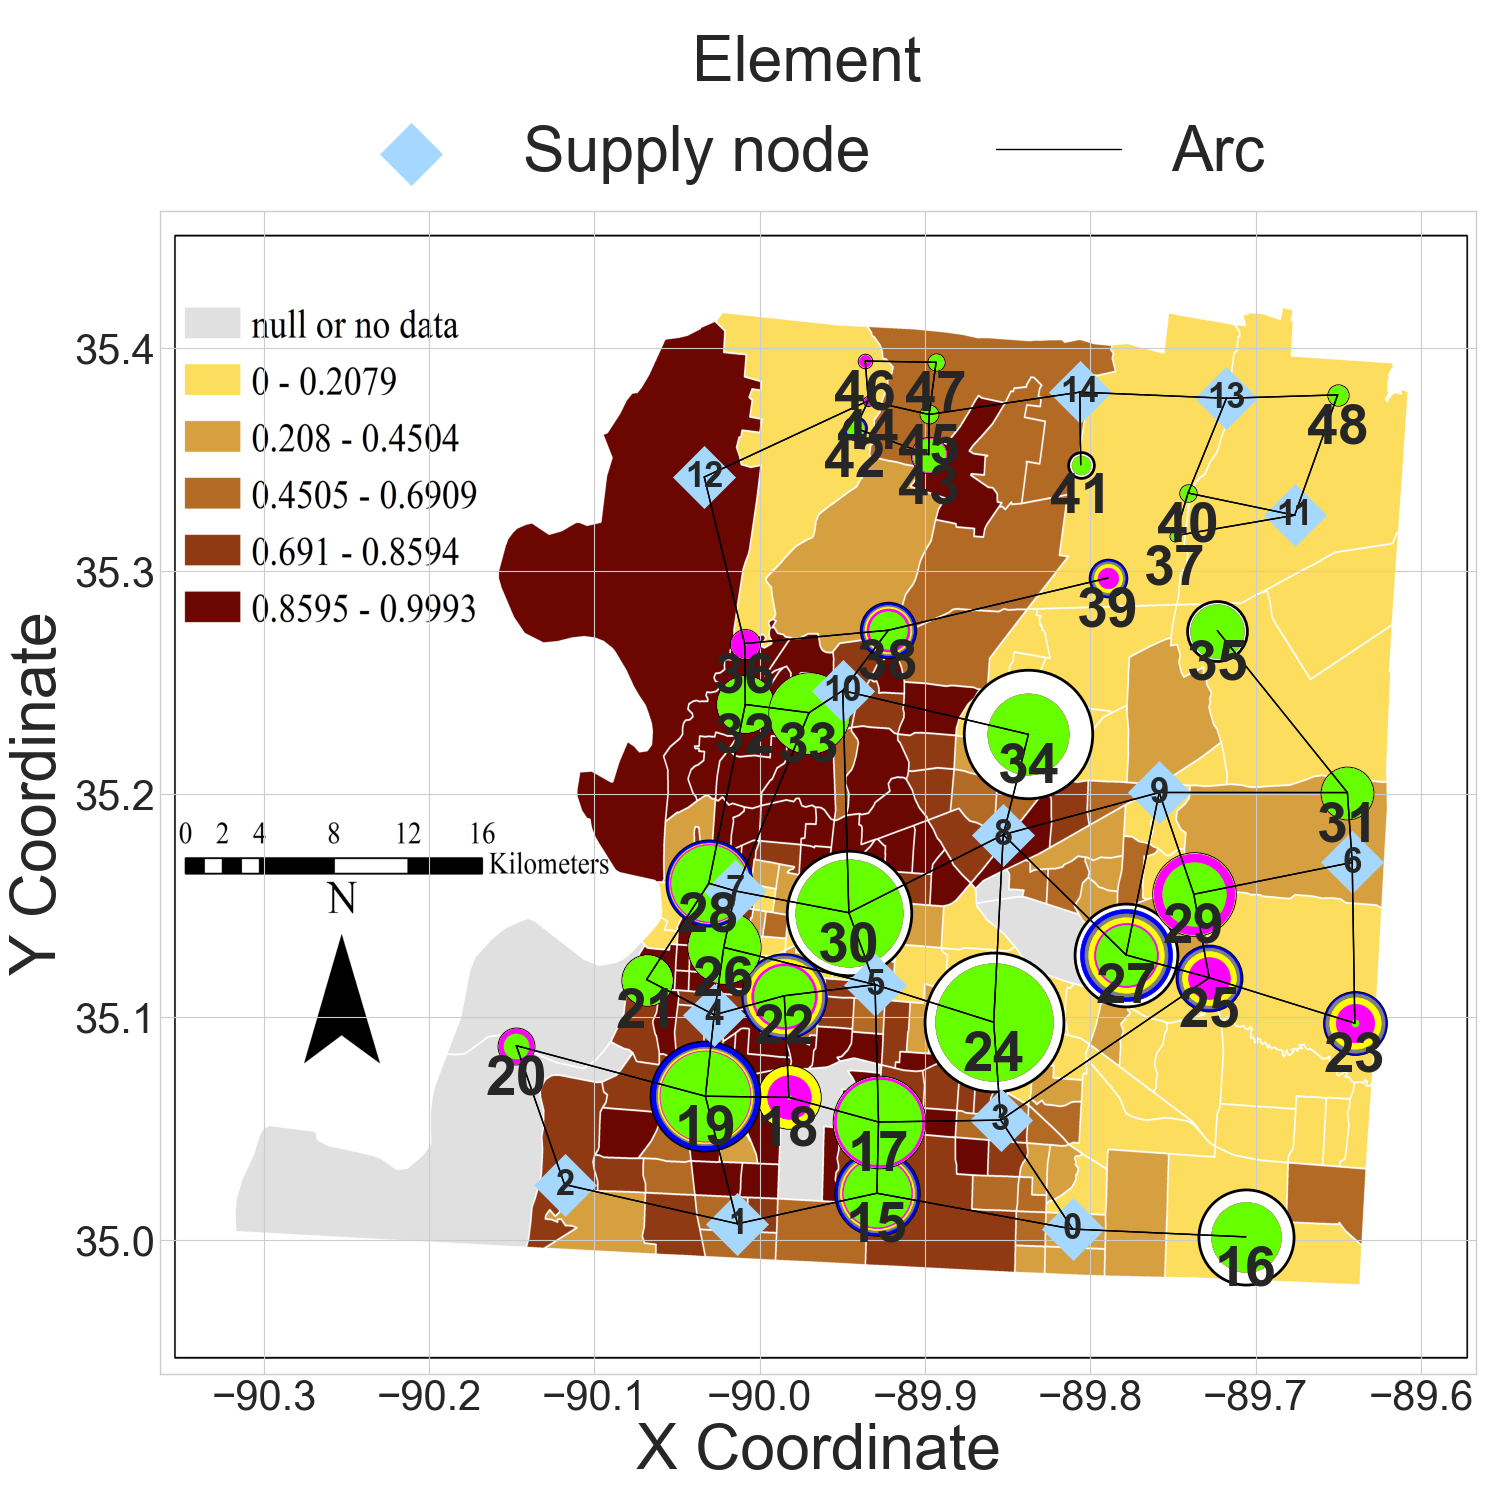

In [21]:
#WATER
xmin = min(x_coord['Gas'].values())-0.2  # Minimum x-coordinate
xmax = max(x_coord['Gas'].values())+0.06  # Maximum x-coordinate
ymin = min(y_coord['Gas'].values())-0.055  # Minimum y-coordinate
ymax = max(y_coord['Gas'].values())+0.12  # Maximum y-coordinate

for scarcity_level in scarce:
    print(f'\n------------{scarcity_level}------------')
    fig, ax = plt.subplots(figsize=(15, 15))
    # Display the image as the background
    ax.imshow(img, extent=[xmin, xmax, ymin, ymax],aspect = 'auto')  # Set the extent based on your data limits
    colors = {'Gas': 'silver', 'Power': '#B2FFB2', 'Water': '#A6D8FF'}
    labels = {'Gas': [], 'Power': [], 'Water': []}
    label_done = {'Gas': {'S':False,'T':False,'D':False}, 'Power': {'S':False,'T':False,'D':False}, 'Water': {'S':False,'T':False,'D':False}}
    thy_size = 1000
    node_type = 'Water'
    max_demand_value = max_demand[node_type]
    base = 10000
    neon_green = [(0.4, 1.0, 0.0)]
    for number in list(water_allocation_data[scarcity_level]['node'])+supply_nodes[node_type]+transshipment_nodes[node_type]:

        x = x_coord[node_type][number]
        y = y_coord[node_type][number]
        
        if number in supply_nodes[node_type]:

            if not label_done[node_type]['S']:
                plt.scatter(x, y, marker='D', s=thy_size, color=colors[node_type], label = 'Supply node')
                label_done[node_type]['S'] = True
            else:
                plt.scatter(x, y, marker='D', s=thy_size, color=colors[node_type])

            plt.text(x, y, number, fontsize=25, ha='center', va='center',  weight='bold')

        elif number in transshipment_nodes[node_type]:
            if not label_done[node_type]['T']:
                plt.scatter(x, y, marker='s', s=thy_size, color=colors[node_type], label = 'Transshipment node')
                label_done[node_type]['T'] = True
            else:
                plt.scatter(x, y, marker='s', s=thy_size, color=colors[node_type])

            plt.text(x, y, number, fontsize=25, ha='center', va='center',  weight='bold')

        else:
        
            node_demand = demand[node_type][number]
            max_val = water_allocation_data[scarcity_level][water_allocation_data[scarcity_level]['node'] == number]['max']
            Q3 = water_allocation_data[scarcity_level][water_allocation_data[scarcity_level]['node'] == number]['q3']
            median = water_allocation_data[scarcity_level][water_allocation_data[scarcity_level]['node'] == number]['median']
            Q1 = water_allocation_data[scarcity_level][water_allocation_data[scarcity_level]['node'] == number]['q1']
            min_val = water_allocation_data[scarcity_level][water_allocation_data[scarcity_level]['node'] == number]['min']
        
#             if not label_done[node_type]['D']:
#                 plt.scatter(x, y, marker='o', edgecolor='k', s= thy_size, facecolor='white', linewidth = 2, label = 'Demand node')
#                 label_done[node_type]['D'] = True
#             else:    

            plt.scatter(x, y, marker='o', edgecolor='k', s= node_demand/max_demand_value*base, facecolor='white', linewidth = 2)
            plt.scatter(x, y, marker='o', s= max_val/max_demand_value*base , color='blue')
            plt.scatter(x, y, marker='o', s= Q3/max_demand_value*base, color='grey')
            plt.scatter(x, y, marker='o', s= median/max_demand_value*base, color='yellow')
            plt.scatter(x, y, marker='o', s= Q1/max_demand_value*base, color='magenta')
            plt.scatter(x, y, marker='o', s= min_val/max_demand_value*base, color=neon_green)
            
            plt.text(x, y-0.015, number, fontsize=40, ha='center', va='center',  weight='bold')


    # Plot lines connecting nodes from list A (in black)
    arc_label = False
    for arc in A_k[node_type]:

        start_node, end_node = arc
        start_x, start_y = x_coord[node_type][start_node], y_coord[node_type][start_node]
        end_x, end_y = x_coord[node_type][end_node], y_coord[node_type][end_node]

        if not arc_label:
            plt.plot([start_x, end_x], [start_y, end_y], linestyle = 'solid', color='black', linewidth = 1, label = 'Arc')
            arc_label = True
        else:
            plt.plot([start_x, end_x], [start_y, end_y], linestyle = 'solid', color='black', linewidth = 1)

    # Show the plot with legend
#     legend = plt.legend(title='Element', bbox_to_anchor=(1.05, 1), loc='upper left', prop={'size': 45}, fontsize = 45)
    legend = plt.legend(title='Element', bbox_to_anchor=(0.1, 1.2), loc='upper left', prop={'size': 45}, fontsize = 45, ncol = 3)
    legend.get_title().set_fontsize(45)

    plt.tick_params(axis='x', labelsize=30)
    plt.xlabel('X Coordinate', fontsize = 45)
    plt.ylabel('Y Coordinate', fontsize = 45)
    plt.tick_params(axis='y', labelsize=30)
    #         plt.title(f"t = {t}, KKT solution", fontsize = 25)

    # Show the plot
    plt.grid(True)
    
#     # Add the saved image to the center bottom of the figure
#     img = plt.imread('results_label.png')
#     # Calculate the position and size of the added image
#     img_height = fig.bbox.height * 0.2  # Adjust the size as needed
#     img_width = img_height * img.shape[1] / img.shape[0]
#     img_x = fig.bbox.width - img_width/0.273
#     img_y = (fig.bbox.y0 + fig.bbox.height)/2 *0.65  # Adjust the vertical position as needed
    
#     # Add the image with adjusted position and size
#     fig.figimage(img, xo=img_x, yo=img_y, origin='upper', alpha=0.8)  # Adjust alpha as needed

    
    # Adjust the layout to ensure everything fits properly
    plt.tight_layout()
    
    fig.savefig(f'{node_type}_network_scarcity_level_{scarcity_level}_dispersion_on_map.pdf', format='pdf', bbox_inches = 'tight')
#     fig.savefig(f'{node_type}_network_scarcity_level_{scarcity_level}_dispersion_on_map.png', bbox_inches = 'tight')
    plt.show()
    